# Light-curve analysis — TESS, environment and SPECULOOS

## Context

This notebook prepares the light-curve products of one eclipsing white dwarf + M dwarf (WD+MS) candidate. For that target it:

1. downloads TESS cutouts (TESSCut) and extracts a PSF-weighted light curve;
2. cleans and detrends it, finds the period with a BLS search, and refines the period and the mid-eclipse time T0 with SPECULOOS eclipses when they are available, ending with a linear ephemeris `T_mid = T0 + E·P`;
3. maps the pixels around the target, to check that the eclipse comes from the target and not from a neighbouring star;
4. fits the SPECULOOS eclipses of any target jointly in all its bands and plots them. It prints the eclipse depth per band (the `depth_by_filter` values of Part 2), and its figure is reused as the light-curve panel of the composite figure made by the SED–dilution pipeline (`2_sed_dilution/main_all.py`).

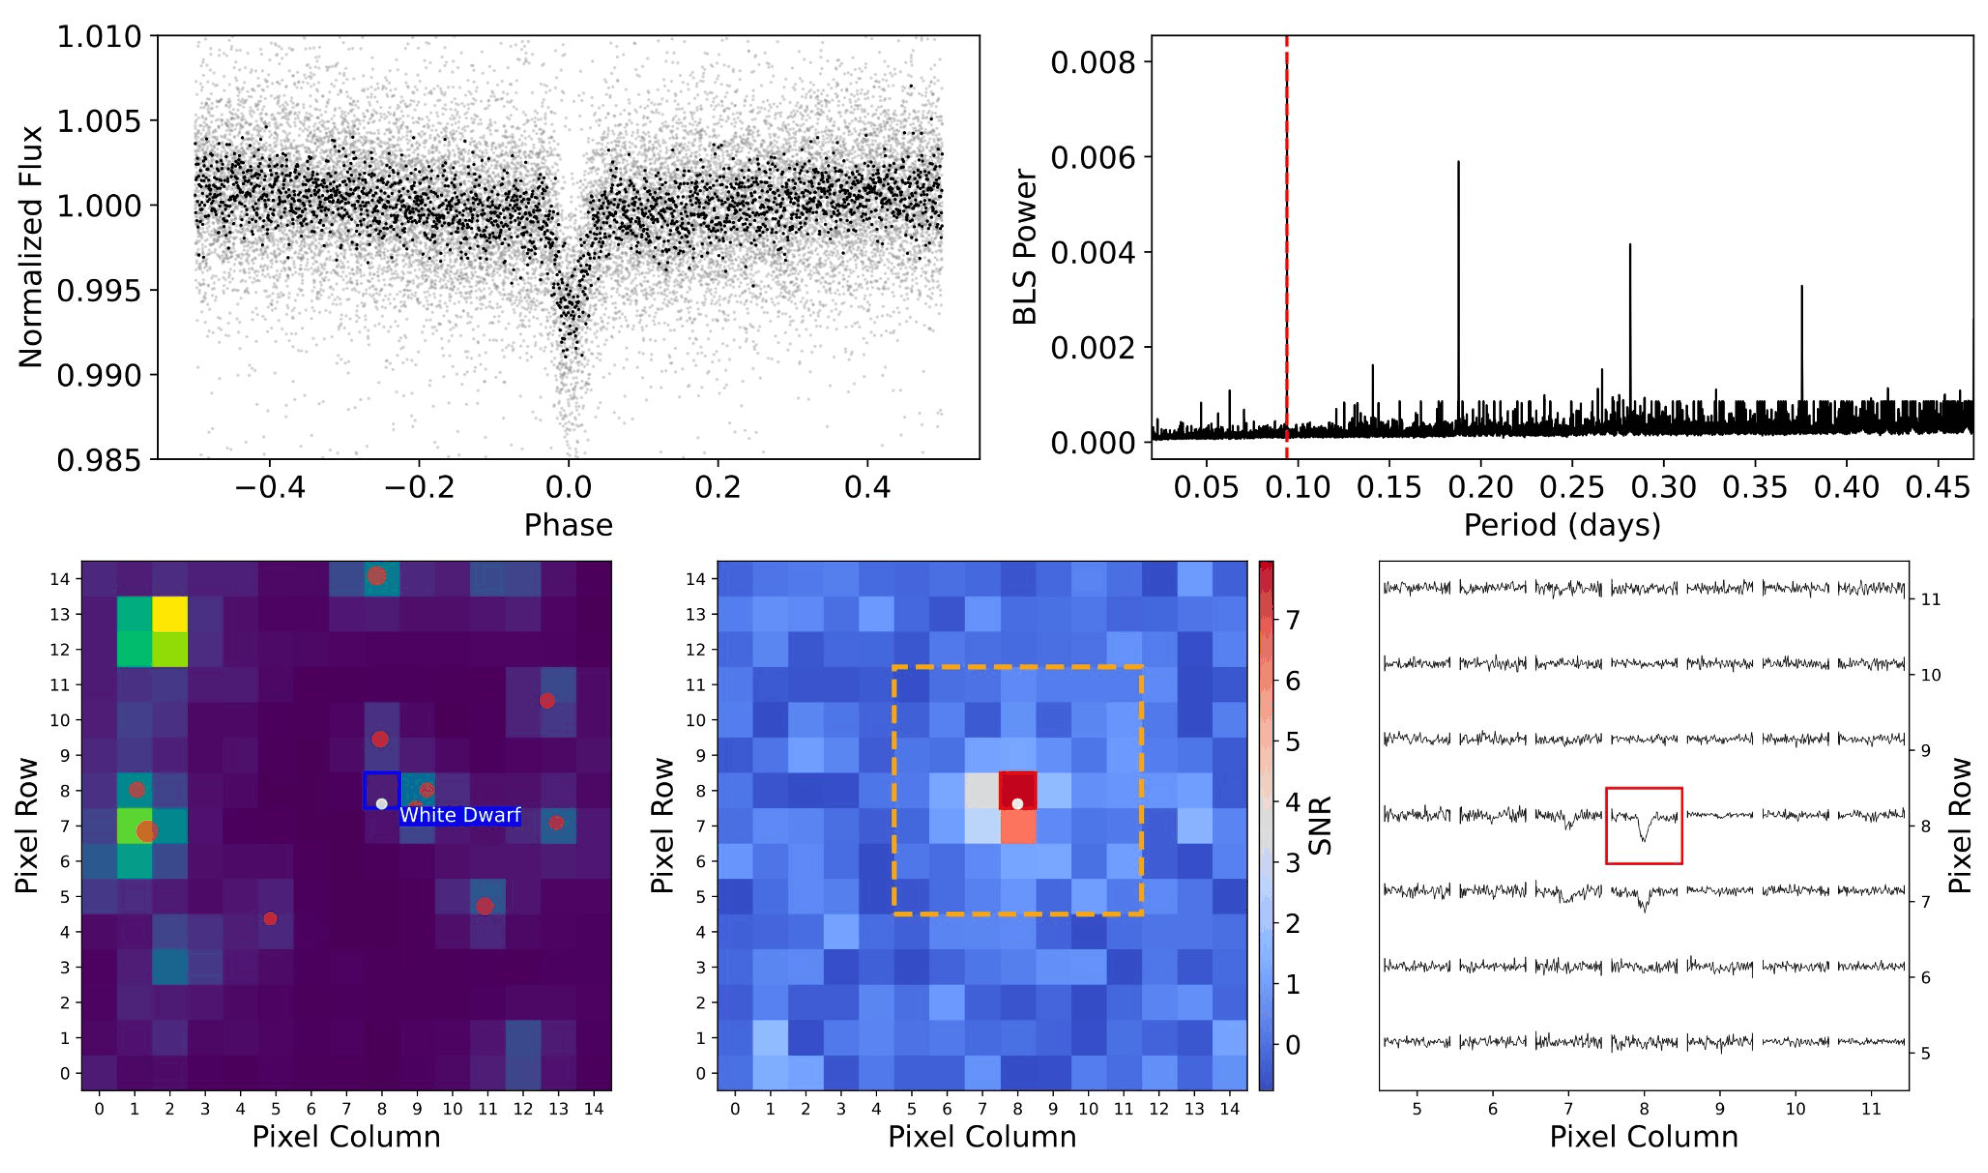

*Example outputs for a short-period eclipsing system (BLS period ≈ 0.094 d).*

- **Top left:** the TESS light curve folded on the period (grey: individual cadences, black: binned), with the eclipse at phase 0.
- **Top right:** the BLS periodogram. The red dashed line marks the BLS period; the other peaks fall at multiples of it.
- **Bottom left:** the median TESS target-pixel image with the Gaia DR3 sources (red dots, larger for brighter stars). The white dwarf's pixel is outlined in blue.
- **Bottom centre:** the per-pixel transit signal-to-noise map, which peaks on the white dwarf's pixel. The orange dashed box is the region shown on the right.
- **Bottom right:** the folded light curve of each pixel in that region. The eclipse appears in the target pixel (red box), which shows that the signal comes from the target.

## Folders

Everything is stored in the workspace shared with the SED–dilution pipeline (see `2_sed_dilution/wdms_paths.py`):

```
<DOWNLOADS>/WDMS_fitting_pipeline/TIC<id>/
├── tess_cutouts/            TESSCut FITS files
├── light_curve/             TESS CSV and figures
├── speculoos_csv/           SPECULOOS observation CSVs (you put them here)
├── speculoos_light_curve/   SPECULOOS light-curve figure (used by the pipeline)
├── environment_maps/        pixel maps
└── SED-dilution analysis/   written by main_all.py, not by this notebook
```

`<DOWNLOADS>` is your Downloads folder, found automatically. Set `DOWNLOADS_DIR` in the *Target and folders* cell to use another folder.

## How to use

1. Run the installation cell once (section 0).
2. In the *Target and folders* cell (section 1), set `TIC_ID`.
3. Set `MANUAL_SECTORS` in the download cell (section 2), then `P_init` and, if SPECULOOS eclipses should refine the ephemeris, `SPECULOOS_BANDS` in the settings cell (section 3).
4. Run sections 2 to 5 in order: TESS light curve, period and ephemeris, environment maps.
5. Section 6 (SPECULOOS light curves) is independent of the TESS part. Set `SPECULOOS_TIC_ID` in its cell (it may be another target than `TIC_ID`): the cell reads every CSV in that target's `speculoos_csv/` folder, named `TIC<id>_<band>.csv` with `<band>` = `exo`, `i`, `z` or `iz` (no header: `time_mjd, flux, flux_err`; separator `;`, `,`, tab or space). It only needs the cells of sections 0 and 1 to have run.

Sections:

0. **Setup.** Package installation and imports.
1. **Target and folders.**
2. **TESS download.** TESSCut cutouts and PSF-weighted photometry.
3. **Settings.** Initial period, SPECULOOS bands for the ephemeris, cleaning, BLS grid, figures.
4. **Period and ephemeris.** Cleaning and detrending, BLS, optional SPECULOOS T0s, exposure-integrated trapezoid timing, then `T_mid = T0 + E·P` with `cov(T0, P)`; diagnostic, folded light curve and BLS periodogram.
5. **Environment.** Median TPF + Gaia DR3, transit S/N map, folded light curve in each pixel. PDFs in `environment_maps/`.
6. **SPECULOOS light curves.** Joint exposure-integrated eclipse fit of all bands of one target, depth per band, figure in `speculoos_light_curve/`.


## 0. Setup

Installs missing packages (once) and imports the shared libraries.

In [ ]:
# Install any missing packages into the current kernel. Run once, before the rest of the notebook.
#
# Packages:
#   numpy, pandas, matplotlib, scipy, astropy, astroquery, lightkurve, wotan, certifi

import importlib.util
import subprocess
import sys

PACKAGES = [
    "numpy",
    "pandas",
    "matplotlib",
    "scipy",
    "astropy",
    "astroquery",
    "lightkurve",
    "wotan",
    "certifi",
]

missing = [name for name in PACKAGES if importlib.util.find_spec(name) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All packages are already installed.")


In [ ]:
# Shared imports: numpy, pandas, matplotlib, BLS (astropy), and wotan flattening.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.timeseries import BoxLeastSquares
from scipy.optimize import curve_fit
from astropy.time import Time
import astropy.units as u
from wotan import flatten as wotan_flatten


## 1. Target and folders

Set `TIC_ID` here. Every cell of sections 2–5 uses this target and its folders; section 6 uses the workspace found here.

In [ ]:
# Target and folders: set the target here; every later cell uses these values.
#
# Folders, shared with the SED–dilution pipeline (2_sed_dilution/wdms_paths.py):
#   <DOWNLOADS>/WDMS_fitting_pipeline/TIC<id>/
#       tess_cutouts/  light_curve/  speculoos_csv/  speculoos_light_curve/  environment_maps/
# <DOWNLOADS> is your Downloads folder; set DOWNLOADS_DIR to use another folder.

TIC_ID        = 450781262   # 450781262 or "TIC450781262"
DOWNLOADS_DIR = None        # None = automatic, or e.g. "/path/to/my/downloads"

import os
import re
import sys
from pathlib import Path


def _find_code_dir():
    """Folder holding wdms_paths.py (<repository>/2_sed_dilution/), or None."""
    env = os.environ.get("WDMS_REPO_DIR")
    roots = ([Path(env)] if env else []) + [Path.cwd(), *Path.cwd().parents]
    for folder in roots:
        for candidate in (folder, folder / "2_sed_dilution"):
            if (candidate / "wdms_paths.py").is_file():
                return candidate.resolve()
    return None


_repo = _find_code_dir()
if _repo is not None:
    # Same rules as the pipeline, from the repository's wdms_paths.py.
    if str(_repo) not in sys.path:
        sys.path.insert(0, str(_repo))
    import wdms_paths
    _downloads = wdms_paths.resolve_downloads_dir(DOWNLOADS_DIR, "DOWNLOADS_DIR")
    workspace  = wdms_paths.workspace_dir(_downloads)
    tic_id     = wdms_paths.tic_label(TIC_ID)
else:
    # Stand-alone copy of the notebook: the same rules, without the Windows
    # registry / Linux XDG lookups of wdms_paths.py.
    _m = re.fullmatch(r"\s*(?:tic)?[\s_\-:]*0*(\d+)\s*", str(TIC_ID), re.IGNORECASE)
    if not _m or int(_m.group(1)) <= 0:
        raise ValueError(f"Invalid TIC_ID: {TIC_ID!r}")
    tic_id = f"TIC{int(_m.group(1))}"
    _explicit = DOWNLOADS_DIR or os.environ.get("WDMS_DOWNLOADS_DIR")
    if _explicit:
        _downloads = Path(os.path.expanduser(str(_explicit))).resolve()
        if not _downloads.is_dir():
            raise FileNotFoundError(f"DOWNLOADS_DIR does not exist: {_downloads}")
    else:
        _downloads = next((p for p in (Path.home() / "Downloads", Path.home() / "Téléchargements")
                           if p.is_dir()), None)
        if _downloads is None:
            raise FileNotFoundError("No Downloads folder found: set DOWNLOADS_DIR.")
    workspace = _downloads / "WDMS_fitting_pipeline"

TIC_ID = int(tic_id[3:])                      # numeric form, used by the TESS download
downloads_dir     = os.fspath(_downloads)
base_dir          = os.fspath(workspace)      # folder holding every TIC<id>/ folder
target_dir        = os.path.join(base_dir, tic_id)
cutout_dir        = os.path.join(target_dir, "tess_cutouts")
lc_dir            = os.path.join(target_dir, "light_curve")
env_dir           = os.path.join(target_dir, "environment_maps")
speculoos_csv_dir = os.path.join(target_dir, "speculoos_csv")
speculoos_lc_dir  = os.path.join(target_dir, "speculoos_light_curve")
csv_path          = os.path.join(lc_dir, f"{tic_id}_allsectors.csv")
output_dir        = lc_dir
for _subdir in (cutout_dir, lc_dir, speculoos_csv_dir, speculoos_lc_dir, env_dir):
    os.makedirs(_subdir, exist_ok=True)

print(f"Target          : {tic_id}")
print(f"Workspace       : {base_dir}")
print(f"Target folder   : {target_dir}")
print(f"SPECULOOS CSVs  : {speculoos_csv_dir}")


## 2. TESS download

TESSCut cutouts of the chosen sectors and a PSF-weighted light curve, saved as `light_curve/TIC<id>_allsectors.csv`. Set `MANUAL_SECTORS` in the second cell.

In [ ]:
# TESSCut helpers: TIC coordinates, cutout download, and PSF-weighted photometry.
import os
import gc
import time 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astroquery.mast import Catalogs, Tesscut
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.io import fits
from lightkurve.targetpixelfile import TessTargetPixelFile
from lightkurve import LightCurve
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter
from matplotlib.patches import Rectangle

import os, certifi
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
# ============================================================
# 1. Build a minimal "master table" for a list of TIC IDs
#    -> returns tic_id, ra, dec
# ============================================================

def build_master_minimal(tic_id_list):
    """
    Query TIC catalog for each TIC ID, keep only tic_id / ra / dec.
    Returns a pandas.DataFrame with columns ['tic_id','ra','dec'].
    """
    tic_ids_int = [int(t) for t in tic_id_list]

    # Query TIC
    tic_tbl = Catalogs.query_criteria(catalog="TIC", ID=tic_ids_int)
    tic_tbl = tic_tbl['ID', 'ra', 'dec']  # only what we need

    # Convert to pandas and clean
    df = tic_tbl.to_pandas().rename(columns={'ID': 'tic_id'})
    df['tic_id'] = df['tic_id'].astype(int)

    # Reorder rows to match input tic_id_list order
    df = df.set_index('tic_id').loc[tic_ids_int].reset_index()

    return df


# ============================================================
# 2. Download one TESSCut cutout per TIC/sector if not present
# ============================================================

def download_cutout_single(tic_id, ra, dec, sector, output_dir, size=15):
    """
    Download a 15x15 (default) TESSCut cutout for (ra, dec) in this sector
    and save to output_dir/tesscut_TIC{tic_id}_sector{sector}.fits
    if not already present.
    """
    os.makedirs(output_dir, exist_ok=True)

    cutout_path = os.path.join(
        output_dir,
        f"tesscut_TIC{tic_id}_sector{sector}.fits"
    )

    if os.path.exists(cutout_path):
        print(f"[OK] Cutout already exists: {cutout_path}")
        return cutout_path

    try:
        coord = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg))
        cutouts = Tesscut.get_cutouts(coordinates=coord, size=size, sector=sector)

        # Tesscut.get_cutouts returns a list-like of HDULists.
        # We assume first element is the cutout we need.
        if len(cutouts) == 0:
            raise RuntimeError("No cutout returned by Tesscut")

        hdul = cutouts[0]
        hdul.writeto(cutout_path, overwrite=True)
        print(f"[SAVED] {cutout_path}")
        return cutout_path

    except Exception as e:
        print(f"[FAIL] TIC {tic_id} sector {sector}: {e}")
        return None


# ============================================================
# 3. Extract the PSF-weighted light curve for one sector
# ============================================================

def extract_psf_weighted_lc(tic_id, ra, dec, sector, cutout_path,
                            debug_plot=False,
                            cadence_limit_min=15.0):
    """
    Open the FITS cutout as a TessTargetPixelFile,
    build a PSF mask around the target,
    and extract the PSF-weighted flux.
    Returns a DataFrame with TIME, FLUX, SECTOR.
    Returns None if the cadence is slower than cadence_limit_min.
    """

    if cutout_path is None or (not os.path.exists(cutout_path)):
        print(f"[SKIP] No cutout file for TIC {tic_id} sector {sector}")
        return None

    # Open the cutout as a TPF
    tpf = TessTargetPixelFile(cutout_path)

    # Cadence in minutes
    dt_days = np.median(np.diff(tpf.time.value))
    cadence_min = dt_days * 24.0 * 60.0
    print(f"TIC {tic_id} sector {sector}: cadence ~ {cadence_min:.2f} min")

    # if cadence_min > cadence_limit_min:
    #     print(f"[SKIP] TIC {tic_id} sector {sector}: cadence too long")
    #     try:
    #         # close the FITS file
    #         tpf.hdu.close()
    #     except Exception:
    #         pass
    #     del tpf
    #     gc.collect()
    #     return None

    # Target (RA, Dec) projected to cutout pixel coordinates
    coord = SkyCoord(ra, dec, unit="deg")
    x0, y0 = tpf.wcs.world_to_pixel(coord)
    x0, y0 = float(x0), float(y0)

    # Median image used to estimate the PSF
    median_img = np.nanmedian(tpf.flux.value, axis=0)

    # Replace NaN/inf if needed
    bad_pixels = np.isnan(median_img).sum() + np.isinf(median_img).sum()
    if bad_pixels > 0:
        print(f"[WARN] {bad_pixels} non-finite px in median image TIC {tic_id} sector {sector}")
        median_img = np.nan_to_num(median_img, nan=0.0, posinf=0.0, neginf=0.0)

    ny, nx = median_img.shape
    iy, ix = int(round(y0)), int(round(x0))

    # Target pixel must lie inside the image
    if not (0 <= iy < ny and 0 <= ix < nx):
        print(f"[SKIP] TIC {tic_id} sector {sector}: target pixel out of bounds "
              f"(x={ix}, y={iy}) for shape=({ny},{nx})")
        try:
            tpf.hdu.close()
        except Exception:
            pass
        del tpf
        gc.collect()
        return None

    # Simple Gaussian PSF, fixed center (x0, y0) and width
    sigma_guess = 1.5
    amp0 = median_img[iy, ix]

    gauss = Gaussian2D(
        amplitude=amp0,
        x_mean=x0, y_mean=y0,
        x_stddev=sigma_guess, y_stddev=sigma_guess
    )
    # Freeze everything except the amplitude (keep center and width fixed)
    gauss.x_mean.fixed = True
    gauss.y_mean.fixed = True
    gauss.x_stddev.fixed = True
    gauss.y_stddev.fixed = True

    # Fit the amplitude on the median image
    y_inds, x_inds = np.indices(median_img.shape)
    fitter = LevMarLSQFitter()
    best_med = fitter(gauss, x_inds, y_inds, median_img)

    # Model PSF
    psf_stamp = best_med(x_inds, y_inds)

    # Core-PSF pixel mask (above 80% of the peak)
    threshold = 0.8 * psf_stamp.max()
    mask_core = psf_stamp > threshold

    # Optional debug plot of the PSF and selected pixels
    if debug_plot:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(median_img, origin='lower', cmap='gray')
        ax.scatter(x0, y0, marker='x', color='red', s=60, lw=1.5, label='target')
        ys, xs = np.where(mask_core)
        for yy, xx in zip(ys, xs):
            ax.add_patch(Rectangle((xx-0.5, yy-0.5), 1, 1,
                                   edgecolor='cyan', facecolor='none', lw=1.0))
        ax.set_title(f"TIC {tic_id} sector {sector}")
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")
        ax.legend(loc='upper right')
        plt.tight_layout()
        plt.show()

    # PSF-weighted photometry
    flux_cube = tpf.flux.value           # (ntime, ny, nx)
    flux_sel = flux_cube[:, mask_core]   # (ntime, nselpix)

    psf_vals = psf_stamp[mask_core]
    weights = psf_vals / psf_vals.sum()  # normalized weights

    wd_flux = np.dot(flux_sel, weights)  # (ntime,)

    # Propagated uncertainty
    err_cube = tpf.flux_err.value[:, mask_core]  # (ntime, nselpix)
    wd_err = np.sqrt(np.dot(err_cube**2, weights**2))

    # LightCurve object (not required, but keeps the extraction tidy)
    lc = LightCurve(
        time=tpf.time.value,
        flux=wd_flux,
        flux_err=wd_err
    )

    # Output DataFrame for this sector
    df_sector = pd.DataFrame({
        "TIME": lc.time,
        "FLUX": lc.flux,
        "FLUX_ERR": lc.flux_err,
        "SECTOR": np.full_like(lc.time, sector, dtype=int),
        "TIC_ID": np.full_like(lc.time, tic_id, dtype=int)
    })

    # Free memory
    try:
        tpf.hdu.close()
    except Exception:
        pass
    del tpf
    gc.collect()

    return df_sector



def _extract_sector_numbers(sector_table):
    """Turn a TESSCut.get_sectors table into a sorted list of integer sectors."""
    if sector_table is None or len(sector_table) == 0:
        return []

    colnames = list(getattr(sector_table, "colnames", []))
    if "sector" in colnames:
        values = sector_table["sector"]
    elif "sectorName" in colnames:
        values = sector_table["sectorName"]
    else:
        raise ValueError(f"Unexpected columns in the sector table: {colnames}")

    sectors = []
    for value in values:
        text = str(value)
        digits = "".join(ch for ch in text if ch.isdigit())
        if digits:
            sectors.append(int(digits))

    return sorted(set(sectors))


def fetch_ticv82_coordinates(tic_id):
    """
    RA/Dec from the TIC catalog on MAST (TIC v8/v8.2).
    Returns (ra_deg, dec_deg, tic_dataframe).
    """
    try:
        master_df = build_master_minimal([tic_id])
        tic_row = master_df.iloc[0]
        return float(tic_row["ra"]), float(tic_row["dec"]), master_df
    except Exception as exc:
        print(f"[WARN] TIC query by ID failed: {exc}")

    # Softer fallback: MAST object search around the TIC name.
    try:
        tbl = Catalogs.query_object(f"TIC {int(tic_id)}", catalog="TIC", radius=2 * u.arcsec)
        if len(tbl) == 0:
            raise ValueError("No TIC source found via query_object")
        df = tbl["ID", "ra", "dec"].to_pandas().rename(columns={"ID": "tic_id"})
        df["tic_id"] = df["tic_id"].astype(int)
        row = df.iloc[0]
        return float(row["ra"]), float(row["dec"]), df
    except Exception as exc:
        raise RuntimeError(
            f"Could not get RA/Dec from TICv8.2/MAST for TIC {tic_id}"
        ) from exc


def get_tess_visibility_sectors(tic_id, ra_deg=None, dec_deg=None):
    """
    TESS sectors in which the target is observed.

    1) Try the TIC object name (TESSCut / Web Visibility).
    2) If that fails or returns nothing, use TICv8.2 RA/Dec.
    """
    # Method 1: TIC name.
    try:
        tbl = Tesscut.get_sectors(objectname=f"TIC {int(tic_id)}")
        sectors = _extract_sector_numbers(tbl)
        if sectors:
            print(f"[OK] Sectors found via TIC object name: {sectors}")
            return sectors
        print("[WARN] No sector found by TIC object name; falling back to RA/Dec.")
    except Exception as exc:
        print(f"[WARN] Sector search by TIC object name failed: {exc}")

    # Method 2: coordinates.
    if ra_deg is None or dec_deg is None:
        ra_deg, dec_deg, _ = fetch_ticv82_coordinates(tic_id)

    coord = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg, frame="icrs")
    tbl = Tesscut.get_sectors(coordinates=coord)
    sectors = _extract_sector_numbers(tbl)
    if not sectors:
        raise RuntimeError(f"No TESSCut sector found for TIC {tic_id} at RA={ra_deg}, Dec={dec_deg}")

    print(f"[OK] Sectors found via TICv8.2 coordinates: {sectors}")
    return sectors


In [ ]:
# Run the download: chosen sectors, TESSCut cutouts, then the light-curve CSV.
# ============================================================
# Download steps:
#    - RA/Dec from TICv8.2 via MAST
#    - sectors from TESSCut / Web Visibility, or a manual list
#    - for each sector: download the cutout and extract the LC
#    - concatenate and save a CSV
# ============================================================
if __name__ == "__main__":

    # TIC_ID and the folders come from the "Target and folders" cell.

    # None or []: sectors from TESSCut / Web Visibility.
    # Non-empty list: force these sectors.
    MANUAL_SECTORS = [99,100]
    # Example: MANUAL_SECTORS = [54, 81, 92]

    CUTOUT_SIZE = 15
    CADENCE_LIMIT_MIN = 5.0
    # <DOWNLOADS>/WDMS_fitting_pipeline/TIC<id>/{tess_cutouts, light_curve}
    CUTOUT_DIR = cutout_dir
    OUTPUT_CSV = csv_path
    DEBUG_PLOT = False  # True: show the median image and the PSF mask

    # 1) TICv8.2 RA/Dec (needed for Tesscut and for the sector fallback)
    ra_target, dec_target, master_df = fetch_ticv82_coordinates(TIC_ID)
    print(f"[OK] TIC {TIC_ID}: RA={ra_target:.8f} deg, Dec={dec_target:.8f} deg")

    # 2) Sectors: manual list if set, otherwise automatic
    if MANUAL_SECTORS:
        SECTORS = sorted({int(sec) for sec in MANUAL_SECTORS})
        print(f"[INFO] Sectors set manually: {SECTORS}")
    else:
        SECTORS = get_tess_visibility_sectors(TIC_ID, ra_deg=ra_target, dec_deg=dec_target)

    if not SECTORS:
        raise RuntimeError("No sector to download. Check TIC_ID or MANUAL_SECTORS.")

    all_sector_dfs = []

    # 3) Loop over sectors
    for sec in SECTORS:
        print(f"\n=== Sector {sec} ===")

        # 3.a) Download the cutout, or reuse it if it already exists
        cutout_path = download_cutout_single(
            tic_id=TIC_ID,
            ra=ra_target,
            dec=dec_target,
            sector=sec,
            output_dir=CUTOUT_DIR,
            size=CUTOUT_SIZE,
        )

        if cutout_path is None:
            print(f"[WARN] No cutout file for TIC {TIC_ID} sector {sec}")
            continue

        # 3.b) Extract the PSF-weighted light curve
        try:
            df_sec = extract_psf_weighted_lc(
                tic_id=TIC_ID,
                ra=ra_target,
                dec=dec_target,
                sector=sec,
                cutout_path=cutout_path,
                debug_plot=DEBUG_PLOT,
                cadence_limit_min=CADENCE_LIMIT_MIN,
            )
            if df_sec is not None and len(df_sec) > 0:
                all_sector_dfs.append(df_sec)
            else:
                print(f"[WARN] No usable LC for TIC {TIC_ID} sector {sec}")
        except Exception as e:
            print(f"[FAIL] TIC {TIC_ID} sector {sec}: {e}")

    # 4) Merge every light curve and save
    if all_sector_dfs:
        merged_df = pd.concat(all_sector_dfs, ignore_index=True)
        os.makedirs(os.path.dirname(OUTPUT_CSV), exist_ok=True)
        merged_df.to_csv(OUTPUT_CSV, index=False)
        print(f"\n[OK] Saved merged light curve CSV -> {OUTPUT_CSV}")
        print(f"Rows total: {len(merged_df)}")
        print(f"Sectors used: {SECTORS}")
    else:
        print("\n[WARN], No data collected; CSV not written.")


## 3. Settings

Initial period, SPECULOOS bands for the ephemeris, TESS cleaning, BLS grid and figure options.

In [ ]:
# Target settings: TIC, initial period, SPECULOOS, TESS cleaning, BLS grid, and figures.
# ─── Target ─────────────────────────────────────────────────────────────────
# tic_id, TIC_ID and the folders come from the "Target and folders" cell.
P_init  = 0.09389021   # initial period guess [d] for this target

# ─── SPECULOOS ──────────────────────────────────────────────────────────────
# Key = band name  →  CSV path (no header: time_mjd | flux | flux_err)
#                      n_bottom = number of faintest points used for a T0 fallback
# Put those CSVs in <DOWNLOADS>/WDMS_fitting_pipeline/TIC<id>/speculoos_csv/, keeping the same file names.
# Used only to refine T0 and the period of this target (section 4). The SPECULOOS
# light-curve cell (section 6) finds its CSVs by itself and ignores this dictionary.
SPECULOOS_BANDS = {
    # "exo": {
    #     "path"    : os.path.join(speculoos_csv_dir, f"{tic_id}_exo.csv"),
    #     "n_bottom": 2,
    # },
    # "z": {
    #     "path"    : os.path.join(speculoos_csv_dir, f"{tic_id}_z.csv"),
    #     "n_bottom": 2,
    # },
    # "i": {
    #     "path"    : os.path.join(speculoos_csv_dir, f"{tic_id}_i.csv"),
    #     "n_bottom": 2,
    # },
    # "iz": {
    #     "path"    : os.path.join(speculoos_csv_dir, f"{tic_id}_iz.csv"),
    #     "n_bottom": 2,
    # },
}

SPECULOOS_MJD_TO_BTJD = 2_400_000- 2_457_000

# Color per band on the figure (add entries if needed)
SPECULOOS_COLORS = {
    "exo" : "tab:orange",
    "iz"  : "tab:blue",
    "z"   : "tab:purple",
    "r"   : "tab:red",
    "i"   : "tab:green",
}

# SPECULOOS y-limits (None = automatic)
SPECULOOS_YMIN = None
SPECULOOS_YMAX = None

# ─── TESS — cleaning ────────────────────────────────────────────────────────
# Time intervals (BTJD) to drop entirely
TIME_EXCLUSION_INTERVALS = []#(3650,3659),(3630,3645.5)]    # e.g. [(3230, 3235)]

# Time window of the diagnostic figure:
#   None            = auto: if intervals are excluded, center on them with context;
#                     otherwise show the full kept time range.
#   (t_min, t_max)  = explicit BTJD zoom.
DIAG_TIME_FOCUS      = None
DIAG_FOCUS_MARGIN    = 1.0    # context on each side = MARGIN × width of the zone

APPLY_DETRENDING   = True
DETRENDING_METHOD  = "biweight"  # 'biweight', 'median', 'hspline', ...
DETRENDING_WINDOW  = 0.35        # days

OUTLIER_FILTER_PCT = 5.0         # drop this percent of the highest fluxes
MIN_NORM_FLUX      = 0.30        # minimum normalized flux kept (None = off)
MAX_NORM_FLUX      = 1.05      # maximum normalized flux kept (None = off)

# ─── BLS ────────────────────────────────────────────────────────────────────
BLS_PERIOD_SEARCH_FRAC = 0.01
BLS_N_PERIODS          = 5000
BLS_N_DURATIONS        = 50

BLS_N_BOOTSTRAP        = 20
BLS_BOOTSTRAP_SEED     = 42
BLS_BOOTSTRAP_WIN_FRAC = 0.02    # bootstrap window: ±2% around the best P

# Trial durations in HOURS (short transits).
BLS_DURATION_HOURS = (0.25,0.4, 0.6, 0.9, 1.3, 1.8, 2.5, 3.5)

# ─── Individual transit times → ephemeris ──────────────────────────────────
TT_WINDOW_FACTOR   = 2.5     # half-window = FACTOR × T14 duration
TT_MIN_POINTS      = 4       # minimum points in the window to attempt a fit
TT_MIN_IN_TRANSIT  = 2       # minimum points actually inside the transit
TT_MIN_SNR         = 3.0     # minimum SNR (depth/noise·√Nin) to keep a transit
TT_FIT_SHAPE       = False   # True = also fit duration and ingress per TESS transit
TT_OVERSAMPLE      = 10     # model oversampling across the exposure time

# ─── Target and observing plan ──────────────────────────────────────────────
TARGET_RA_DEG   = None       # e.g. 123.456 (deg); None = geocentric correction
TARGET_DEC_DEG  = None       # e.g. -45.678 (deg)
OBS_NOW_UTC     = None       # e.g. "2026-07-09T22:00:00"; None = now
OBS_WINDOW_NSIGMA = 3.0      # window = T_pred ± (Nσ_pred + half the transit duration)

# ─── Display ────────────────────────────────────────────────────────────────
BIN_SIZE             = 10        # binning of the phase-folded TESS LC
TESS_PHASEFOLD_YMIN  = 0.98
TESS_PHASEFOLD_YMAX  = 1.01

# ─── Detrending: mask transits (keeps SNR of shallow events) ────────────────
MASK_TRANSITS_IN_DETRENDING = False
DETRENDING_MASK_FACTOR      = 0.75  # masked half-width = FACTOR × T14
                                    # (keep small for ultra-short P, or too many points are masked)

# ─── Folded fit (high-SNR detection + reference T0) ─────────────────────────
FOLDED_FIT_NBINS   = None   # None = fit the unbinned points; otherwise number of bins
FOLDED_WINDOW_FAC  = 3.0    # folded-fit half-window = FAC × T14

# ─── Precision check ────────────────────────────────────────────────────────
VALID_INJECTIONS = 60       # number of synthetic injections (0 = off)
VALID_SEED       = 1

os.makedirs(output_dir, exist_ok=True)


## 4. Period and ephemeris

Cleaning and detrending, BLS period with a bootstrap, optional SPECULOOS T0s and baseline refinement, exposure-integrated transit times, linear ephemeris, figures and printed summary.

In [ ]:
# Analysis functions: folding, BLS, trapezoid, individual transit times, and a linear ephemeris.
def fold(time, period, T0):
    """Fold into [−0.5, 0.5)."""
    phase = ((time - T0) / period) % 1.0
    phase[phase > 0.5] -= 1.0
    return phase


def bin_lc(phase, flux, bin_size):
    """Median binning, sorted by phase."""
    order = np.argsort(phase)
    ph = phase[order]
    fl = flux[order]
    xs, ys = [], []
    for i in range(0, len(ph), bin_size):
        ph_b = ph[i:i + bin_size]
        fl_b = fl[i:i + bin_size]
        if len(ph_b) == 0:
            continue
        xs.append(np.median(ph_b))
        ys.append(np.median(fl_b))
    return np.array(xs), np.array(ys)


def center_t0_on_dataset(T0_ref, P, time_data):
    """Shift T0_ref to the transit nearest the middle of time_data."""
    t_center = np.nanmedian(time_data)
    n_cycles = np.round((t_center - T0_ref) / P)
    return T0_ref + n_cycles * P


# ── TESS ─────────────────────────────────────────────────────────

def clean_normalize_tess(time_vals, flux_vals,
                         outlier_pct=OUTLIER_FILTER_PCT,
                         time_excl=None,
                         min_norm=MIN_NORM_FLUX,
                         max_norm=MAX_NORM_FLUX):
    mask = np.isfinite(time_vals) & np.isfinite(flux_vals)
    if time_excl:
        for t0, t1 in time_excl:
            if t0 > t1:
                t0, t1 = t1, t0
            mask &= ~((time_vals >= t0) & (time_vals <= t1))
    t = time_vals[mask]
    f = flux_vals[mask]
    if len(t) < 10:
        raise RuntimeError("Not enough valid TESS points after cleaning.")
    if outlier_pct > 0:
        thr  = np.percentile(f, 100.0 - outlier_pct)
        keep = f <= thr
        t = t[keep]
        f = f[keep]
    med = np.nanmedian(f)
    if not np.isfinite(med) or med == 0:
        raise RuntimeError("Invalid flux median.")
    f_norm = f / med
    keep = np.ones(len(f_norm), dtype=bool)
    if min_norm is not None:
        keep &= f_norm >= min_norm
    if max_norm is not None:
        keep &= f_norm <= max_norm
    t      = t[keep]
    f_norm = f_norm[keep]
    return t, f_norm


def apply_detrending_tess(time, flux_norm,
                          method=DETRENDING_METHOD,
                          window=DETRENDING_WINDOW,
                          outlier_pct=OUTLIER_FILTER_PCT,
                          transit_mask=None):
    try:
        _kw = dict(method=method, window_length=window,
                   edge_cutoff=0.5, break_tolerance=0.5,
                   return_trend=True, cval=5.0)
        if transit_mask is not None:
            try:
                flat, _ = wotan_flatten(time, flux_norm, mask=transit_mask, **_kw)
            except TypeError:
                # this wotan build has no 'mask' argument: flatten without masking
                flat, _ = wotan_flatten(time, flux_norm, **_kw)
        else:
            flat, _ = wotan_flatten(time, flux_norm, **_kw)
        print(f"[OK] Detrending OK — method={method}, window={window} d")
    except Exception as e:
        print(f"[WARN] Detrending failed ({e}). Using the normalized raw flux.")
        return time, flux_norm
    if outlier_pct > 0:
        finite = np.isfinite(flat)
        if np.sum(finite) >= 10:
            thr  = np.percentile(flat[finite], 100.0 - outlier_pct)
            keep = flat <= thr
            if np.sum(keep) >= 50:
                n_rem = int(np.sum(~keep))
                time  = time[keep]
                flat  = flat[keep]
                print(f"[OK] Post-detrending outliers removed: {n_rem} points")
    return time, flat


def run_bls(time, flux, p_init,
            search_frac=BLS_PERIOD_SEARCH_FRAC,
            n_periods=BLS_N_PERIODS,
            n_durations=BLS_N_DURATIONS):
    mask = np.isfinite(time) & np.isfinite(flux)
    t = time[mask]
    f = flux[mask]
    pmin      = p_init * (1.0 - search_frac)
    pmax      = p_init * (1.0 + search_frac)
    periods   = np.linspace(pmin, pmax, n_periods)
    durations = np.linspace(0.002, 0.1, n_durations) * p_init
    res  = BoxLeastSquares(t, f).power(periods, durations)
    best = int(np.argmax(res.power))
    return float(res.period[best]), float(res.transit_time[best]), res


def bootstrap_bls_uncertainties(time, flux, best_period, best_t0,
                                 n_bootstrap=BLS_N_BOOTSTRAP,
                                 window_frac=BLS_BOOTSTRAP_WIN_FRAC,
                                 seed=BLS_BOOTSTRAP_SEED):
    """
    1-sigma bootstrap on P and T0_bls by resampling with replacement.
    Each draw's T0 is aligned to the same cycle as best_t0 before the std.
    Returns (P_err, T0_bls_err, n_success).
    """
    mask = np.isfinite(time) & np.isfinite(flux)
    t = time[mask]
    f = flux[mask]
    if len(t) < 50 or best_period <= 0:
        return np.nan, np.nan, 0
    rng       = np.random.default_rng(seed)
    pmin      = best_period * (1.0 - window_frac)
    pmax      = best_period * (1.0 + window_frac)
    periods   = np.linspace(pmin, pmax, 3000)
    durations = np.linspace(0.002, 0.1, 50) * best_period
    p_samp  = []
    t0_samp = []
    for _ in range(int(n_bootstrap)):
        idx = rng.integers(0, len(t), size=len(t))
        tb  = t[idx]
        fb  = f[idx]
        order = np.argsort(tb)
        tb = tb[order]
        fb = fb[order]
        try:
            res   = BoxLeastSquares(tb, fb).power(periods, durations)
            ibest = int(np.argmax(res.power))
            p_b   = float(res.period[ibest])
            t0_b  = float(res.transit_time[ibest])
            t0_aligned = t0_b + np.round((best_t0 - t0_b) / best_period) * best_period
            p_samp.append(p_b)
            t0_samp.append(t0_aligned)
        except Exception:
            continue
    n_ok = len(p_samp)
    if n_ok < 10:
        return np.nan, np.nan, n_ok
    P_err      = float(np.nanstd(p_samp,  ddof=1))
    T0_bls_err = float(np.nanstd(t0_samp, ddof=1))
    return P_err, T0_bls_err, n_ok


def refine_period_baseline(T0_bls, sigma_T0_bls, P_bls, bands_results):
    """
    Refine the period from the TESS → SPECULOOS baseline.
    For each band: N = round((T0_sp - T0_bls) / P_bls)
                   P_est = (T0_sp - T0_bls) / N
                   sigma_P = sqrt(sigma_T0_bls^2 + sigma_T0_sp^2) / |N|
    Inverse-variance weighted mean over all bands.
    Returns (P_refined, sigma_P_refined, estimates).
    """
    weights, p_ests, estimates = [], [], {}
    for band, (_, _, _, T0_sp, sigma_T0_sp) in bands_results.items():
        delta_T = T0_sp - T0_bls
        N = int(np.round(delta_T / P_bls))
        if N == 0:
            print(f"[WARN] Band '{band}': N=0, skipped.")
            continue
        if not (np.isfinite(sigma_T0_bls) and np.isfinite(sigma_T0_sp)):
            print(f"[WARN] Band '{band}': missing uncertainty, skipped.")
            continue
        P_est       = delta_T / N
        sigma_P_est = np.sqrt(sigma_T0_bls**2 + sigma_T0_sp**2) / abs(N)
        if sigma_P_est <= 0:
            continue
        estimates[band] = (N, P_est, sigma_P_est)
        w = 1.0 / sigma_P_est**2
        weights.append(w)
        p_ests.append(P_est * w)
    if not weights:
        print("[WARN] Period refinement failed: no usable band.")
        return P_bls, np.nan, estimates
    W           = sum(weights)
    P_refined   = sum(p_ests) / W
    sigma_P_ref = 1.0 / np.sqrt(W)
    return P_refined, sigma_P_ref, estimates


# ── SPECULOOS ─────────────────────────────────────────────────────

def load_speculoos_band(path, n_bottom, mjd_offset=SPECULOOS_MJD_TO_BTJD):
    """
    Load a SPECULOOS CSV (no header: time_mjd, flux, flux_err).
    Detect the separator, skip comments (#),
    coerce to numbers, and drop unparseable rows.
    Returns time_btjd, flux_norm, flux_err_norm, T0, T0_err
    """
    df = pd.read_csv(
        path, header=None,
        names=["time_mjd", "flux", "flux_err"],
        sep=None, engine="python", comment="#",
    )
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
    if len(df) == 0:
        raise ValueError(
            f"File '{path}' has no valid numeric row. "
            "Check the separator, comments, and columns."
        )
    time_btjd = df["time_mjd"].to_numpy(float) + mjd_offset
    flux      = df["flux"].to_numpy(float)
    flux_err  = df["flux_err"].to_numpy(float)
    order     = np.argsort(time_btjd)
    time_btjd = time_btjd[order]
    flux      = flux[order]
    flux_err  = flux_err[order]
    n_pts = len(flux)
    n_bot = min(int(n_bottom), n_pts)
    idx_bottom = np.argsort(flux)[:n_bot]
    mask_oot = np.ones(n_pts, dtype=bool)
    mask_oot[idx_bottom] = False
    med_oot = np.nanmedian(flux[mask_oot]) if np.sum(mask_oot) > 0 else np.nanmedian(flux)
    if not np.isfinite(med_oot) or med_oot == 0:
        med_oot = np.nanmedian(flux)
    flux_norm     = flux     / med_oot
    flux_err_norm = flux_err / med_oot
    t_bottom = time_btjd[idx_bottom]
    T0       = float(np.mean(t_bottom))
    T0_err   = float(np.std(t_bottom, ddof=1) / np.sqrt(n_bot)) if n_bot > 1 else np.nan
    return time_btjd, flux_norm, flux_err_norm, T0, T0_err


def find_last_speculoos_t0(bands_results):
    """T0 and T0_err of the band with the latest time."""
    last_t0, last_t0_err, last_t_max, last_band = None, None, -np.inf, None
    for band, (time, _, _, T0, T0_err) in bands_results.items():
        t_max = float(np.max(time))
        if t_max > last_t_max:
            last_t_max, last_t0, last_t0_err, last_band = t_max, T0, T0_err, band
    print(f"[OK] Reference T0: band '{last_band}' (t_max = {last_t_max:.4f} BTJD)")
    return last_t0, last_t0_err, last_band


# ==========================================================================
#  SHORT TRANSITS — trapezoid model, individual timing, linear ephemeris
# ==========================================================================

def _trapezoid_flux(t, t0, depth, W, tau, baseline):
    """Symmetric trapezoid. W = full duration (T14), tau = ingress/egress duration."""
    t    = np.asarray(t, dtype=float)
    dt   = np.abs(t - t0)
    half = 0.5 * float(W)
    tau  = float(np.clip(tau, 1e-6, max(half, 1e-6)))
    flat = half - tau
    flux = np.full_like(t, float(baseline))
    flux[dt <= flat] = baseline - depth
    edge = (dt > flat) & (dt < half)
    if np.any(edge):
        frac = (half - dt[edge]) / tau            # 1 at the flat bottom, 0 at contact
        flux[edge] = baseline - depth * np.clip(frac, 0.0, 1.0)
    return flux


def trapezoid_model(t, t0, depth, W, tau, baseline, exp_time=0.0, oversample=1):
    """Trapezoid integrated over the exposure (undoes smearing of short transits)."""
    t = np.asarray(t, dtype=float)
    if exp_time and exp_time > 0 and oversample and oversample > 1:
        offs = (np.arange(oversample) - (oversample - 1) / 2.0) / oversample * exp_time
        acc  = np.zeros_like(t)
        for o in offs:
            acc += _trapezoid_flux(t + o, t0, depth, W, tau, baseline)
        return acc / oversample
    return _trapezoid_flux(t, t0, depth, W, tau, baseline)


def _robust_noise(x):
    """Robust scatter (MAD); falls back to the usual std."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 2:
        return np.nan
    mad = np.nanmedian(np.abs(x - np.nanmedian(x)))
    s   = 1.4826 * mad
    if np.isfinite(s) and s > 0:
        return float(s)
    s = float(np.nanstd(x))
    return s if s > 0 else np.nan


def estimate_transit_shape(time, flux, P, T0, dur_grid_hours=BLS_DURATION_HOURS):
    """Global T14 and depth from BLS (duration grid in hours)."""
    m = np.isfinite(time) & np.isfinite(flux)
    t, f = time[m], flux[m]
    durations = np.array(dur_grid_hours, dtype=float) / 24.0
    durations = durations[(durations > 0) & (durations < 0.9 * P)]
    if durations.size == 0:
        durations = np.array([0.05 * P])
    res  = BoxLeastSquares(t, f).power(np.array([P]), durations)
    ib   = int(np.argmax(np.atleast_1d(res.power)))
    W     = float(np.atleast_1d(res.duration)[ib])
    depth = float(np.atleast_1d(res.depth)[ib])
    t0    = float(np.atleast_1d(res.transit_time)[ib])
    return W, max(depth, 1e-4), t0


def fit_single_transit(t, f, t0_guess, W, tau, exp_time,
                       ferr=None, fit_shape=TT_FIT_SHAPE, oversample=TT_OVERSAMPLE):
    """Fit one transit (trapezoid). Returns dict(t0, t0_err, depth, snr, n_in, ok)."""
    t = np.asarray(t, float); f = np.asarray(f, float)
    half   = 0.5 * W
    in_tr  = np.abs(t - t0_guess) <= half
    oot    = ~in_tr
    n_in   = int(np.count_nonzero(in_tr))
    base0  = float(np.nanmedian(f[oot])) if np.count_nonzero(oot) >= 1 else float(np.nanmedian(f))
    depth0 = max(base0 - float(np.nanmin(f)), 1e-4)
    if ferr is not None and np.all(np.isfinite(ferr)) and np.all(np.asarray(ferr) > 0):
        sigma = np.asarray(ferr, float)
    else:
        s = _robust_noise(f[oot]) if np.count_nonzero(oot) >= 3 else _robust_noise(f)
        if not (np.isfinite(s) and s > 0):
            s = float(np.nanstd(f)) or 1.0
        sigma = np.full_like(t, s)
    sig_scalar = float(np.nanmedian(sigma))
    try:
        if fit_shape:
            p0 = [t0_guess, depth0, W, tau, base0]
            lb = [t0_guess - half, 0.0,          0.2 * W, 1e-4, base0 - 5 * depth0]
            ub = [t0_guess + half, 10 * depth0,  3.0 * W, half, base0 + 5 * depth0]
            fun = lambda tt, a, b, c, d, e: trapezoid_model(tt, a, b, c, d, e, exp_time, oversample)
        else:
            p0 = [t0_guess, depth0, base0]
            lb = [t0_guess - half, 0.0,         base0 - 5 * depth0]
            ub = [t0_guess + half, 10 * depth0, base0 + 5 * depth0]
            fun = lambda tt, a, b, e: trapezoid_model(tt, a, b, W, tau, e, exp_time, oversample)
        popt, pcov = curve_fit(fun, t, f, p0=p0, sigma=sigma, absolute_sigma=True,
                               bounds=(lb, ub), maxfev=20000)
        t0_fit  = float(popt[0]); t0_err = float(np.sqrt(np.abs(pcov[0, 0])))
        depth_f = float(popt[1])
        snr     = depth_f / sig_scalar * np.sqrt(max(n_in, 1)) if sig_scalar > 0 else np.nan
        ok = (np.isfinite(t0_fit) and np.isfinite(t0_err) and t0_err > 0 and depth_f > 0)
        return dict(t0=t0_fit, t0_err=t0_err, depth=depth_f, snr=snr, n_in=n_in, ok=ok)
    except Exception:
        return dict(t0=np.nan, t0_err=np.nan, depth=np.nan, snr=np.nan, n_in=n_in, ok=False)


def collect_transit_times(time, flux, P, T0, W, tau,
                          window_factor=TT_WINDOW_FACTOR,
                          min_points=TT_MIN_POINTS,
                          min_in_transit=TT_MIN_IN_TRANSIT,
                          min_snr=TT_MIN_SNR,
                          fit_shape=TT_FIT_SHAPE, oversample=TT_OVERSAMPLE):
    """Scan every covered epoch and fit each transit.
    Returns (epochs, tmids, tmid_errs, info_list)."""
    m = np.isfinite(time) & np.isfinite(flux)
    t, f = time[m], flux[m]
    order = np.argsort(t); t, f = t[order], f[order]
    if t.size < min_points:
        return np.array([]), np.array([]), np.array([]), []
    half_win = window_factor * W
    E_lo = int(np.floor((t.min() - T0) / P))
    E_hi = int(np.ceil((t.max() - T0) / P))
    epochs, tmids, errs, info = [], [], [], []
    for E in range(E_lo, E_hi + 1):
        tc  = T0 + E * P
        sel = np.abs(t - tc) <= half_win
        n   = int(np.count_nonzero(sel))
        if n < min_points:
            continue
        tw, fw   = t[sel], f[sel]
        exp_time = float(np.median(np.diff(np.sort(tw)))) if tw.size > 1 else 0.0
        r = fit_single_transit(tw, fw, tc, W, tau, exp_time,
                               fit_shape=fit_shape, oversample=oversample)
        r.update(E=E, tc_pred=tc, n_win=n, exp_time=exp_time)
        info.append(r)
        keep = (r["ok"] and r["n_in"] >= min_in_transit
                and np.isfinite(r["snr"]) and r["snr"] >= min_snr
                and abs(r["t0"] - tc) <= half_win)
        r["kept"] = keep
        if keep:
            epochs.append(E); tmids.append(r["t0"]); errs.append(r["t0_err"])
    return (np.array(epochs, float), np.array(tmids, float),
            np.array(errs, float), info)


def fit_linear_ephemeris(epochs, tmids, tmid_errs):
    """Fit T_mid = T0 + E*P (weighted least squares). Returns a dict or None."""
    E = np.asarray(epochs, float); y = np.asarray(tmids, float); s = np.asarray(tmid_errs, float)
    good = np.isfinite(E) & np.isfinite(y) & np.isfinite(s) & (s > 0)
    E, y, s = E[good], y[good], s[good]
    if E.size < 2:
        return None
    w   = 1.0 / s**2
    A   = np.vstack([np.ones_like(E), E]).T
    cov = np.linalg.inv(A.T @ (w[:, None] * A))
    beta = cov @ (A.T @ (w * y))
    T0_fit, P_fit = float(beta[0]), float(beta[1])
    resid = y - (T0_fit + P_fit * E)                      # O - C (days)
    ndof  = max(E.size - 2, 1)
    chi2_red = float(np.sum((resid / s)**2) / ndof)
    return dict(T0=T0_fit, P=P_fit, cov=cov,
                T0_err=float(np.sqrt(cov[0, 0])),
                P_err=float(np.sqrt(cov[1, 1])),
                cov_T0P=float(cov[0, 1]),
                n=int(E.size), chi2_red=chi2_red,
                epochs=E, tmids=y, oc=resid, oc_err=s)


def predict_transit_near(T0, P, cov, t_target_btjd, after=True):
    """Transit nearest to (or the next one after) t_target_btjd, with propagated uncertainty."""
    x = (t_target_btjd - T0) / P
    E = int(np.ceil(x)) if after else int(np.round(x))
    T_pred = T0 + E * P
    var = cov[0, 0] + (E**2) * cov[1, 1] + 2.0 * E * cov[0, 1]
    return E, float(T_pred), float(np.sqrt(max(var, 0.0)))


def now_to_btjd(now_utc=None, ra_deg=None, dec_deg=None):
    """Current time -> BTJD (= BJD_TDB - 2457000). Barycentric correction if RA/Dec are set."""
    t   = Time(now_utc, scale="utc") if now_utc else Time.now()
    tdb = t.tdb
    btjd = float(tdb.jd - 2457000.0)
    if ra_deg is not None and dec_deg is not None:
        try:
            from astropy.coordinates import SkyCoord
            sc  = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg)
            ltt = t.light_travel_time(sc, kind="barycentric")
            btjd = float((tdb + ltt).jd - 2457000.0)
        except Exception:
            pass
    return btjd


def btjd_to_utc(btjd, ra_deg=None, dec_deg=None):
    """BTJD (BJD_TDB) -> UTC Time (geocentric). Removes the barycentric correction if RA/Dec are set."""
    tdb = Time(np.atleast_1d(btjd) + 2457000.0, format="jd", scale="tdb")
    if ra_deg is not None and dec_deg is not None:
        try:
            from astropy.coordinates import SkyCoord
            sc  = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg)
            ltt = tdb.light_travel_time(sc, kind="barycentric")
            tdb = tdb - ltt
        except Exception:
            pass
    return tdb.utc


# ==========================================================================
#  SNR / HIGH-PRECISION DETECTION + PRECISION CHECK
# ==========================================================================

def transit_in_mask(time, P, T0, half_width_days):
    """True where the point is inside the transit (|time from center| <= half-width)."""
    time = np.asarray(time, float)
    ph = ((time - T0) / P + 0.5) % 1.0 - 0.5
    return np.abs(ph) * P <= float(half_width_days)


def fit_folded_transit(time, flux, P, T0, W, tau, ferr=None,
                       nbins=None, window_factor=3.0, oversample=1):
    """Fit a trapezoid to the folded curve (all transits stacked).
    Raises the SNR of short, shallow, or sparsely sampled transits.
    Returns dict(t0_off, t0_off_err, depth, snr, n_in, ok, T0_ref, x, f, e)."""
    time = np.asarray(time, float); flux = np.asarray(flux, float)
    ph = ((time - T0) / P + 0.5) % 1.0 - 0.5          # phase in [-0.5, 0.5)
    x  = ph * P                                        # time from mid-transit (days)
    half_win = window_factor * W
    sel = np.abs(x) <= half_win
    if np.count_nonzero(sel) < 5:
        sel = np.ones_like(x, dtype=bool)
    xs, fs = x[sel], flux[sel]
    es = np.asarray(ferr, float)[sel] if ferr is not None else None
    order = np.argsort(xs); xs, fs = xs[order], fs[order]
    if es is not None:
        es = es[order]
    if nbins and nbins > 0:
        edges = np.linspace(-half_win, half_win, int(nbins) + 1)
        idx = np.digitize(xs, edges) - 1
        xb, fb, eb = [], [], []
        for b in range(int(nbins)):
            m = idx == b
            n = int(np.count_nonzero(m))
            if n == 0:
                continue
            xb.append(float(np.median(xs[m]))); fb.append(float(np.median(fs[m])))
            eb.append(float(np.std(fs[m], ddof=1) / np.sqrt(n)) if n > 1 else np.nan)
        xs = np.array(xb); fs = np.array(fb); es = np.array(eb)
        if (not np.all(np.isfinite(es))) or np.all(es <= 0):
            es = None
    r = fit_single_transit(xs, fs, 0.0, W, tau, 0.0, ferr=es,
                           fit_shape=True, oversample=oversample)
    if not r["ok"]:
        r = fit_single_transit(xs, fs, 0.0, W, tau, 0.0, ferr=es,
                               fit_shape=False, oversample=oversample)
    in_tr = np.abs(xs) <= 0.5 * W
    oot   = ~in_tr
    rms   = _robust_noise(fs[oot]) if np.count_nonzero(oot) >= 3 else _robust_noise(fs)
    n_in  = int(np.count_nonzero(in_tr))
    depth = r.get("depth", np.nan)
    snr   = (depth / rms * np.sqrt(max(n_in, 1))
             if (rms and rms > 0 and np.isfinite(depth)) else np.nan)
    t_center = float(np.nanmedian(time))
    E0 = np.round((t_center - T0) / P)
    T0_ref = T0 + E0 * P + r.get("t0", 0.0)
    return dict(t0_off=r.get("t0", np.nan), t0_off_err=r.get("t0_err", np.nan),
                depth=depth, snr=snr, n_in=n_in, ok=r["ok"],
                T0_ref=float(T0_ref), x=xs, f=fs, e=es)


def pull_stats(values):
    """Mean, standard deviation, and N of an array (NaNs ignored)."""
    v = np.asarray(values, float); v = v[np.isfinite(v)]
    if v.size == 0:
        return np.nan, np.nan, 0
    return (float(np.mean(v)),
            float(np.std(v, ddof=1)) if v.size > 1 else np.nan,
            int(v.size))


def injection_recovery(time, flux, P, T0, W, tau, depth,
                       n_trials=60, seed=1, p_jitter_frac=0.001):
    """Remove the transit, re-inject a known (P, T0), and measure recovered minus injected.
    Returns dict(dP, dT0, pull_P, pull_T0). Empirical test of the real precision."""
    time = np.asarray(time, float); flux = np.asarray(flux, float)
    ph = ((time - T0) / P + 0.5) % 1.0 - 0.5
    x  = ph * P
    resid = flux - (_trapezoid_flux(x, 0.0, depth, W, tau, 1.0) - 1.0)  # flux with the dip removed
    rng = np.random.default_rng(seed)
    dP, dT0, pull_P, pull_T0 = [], [], [], []
    for _ in range(int(n_trials)):
        P_in  = P * (1.0 + rng.uniform(-p_jitter_frac, p_jitter_frac))
        T0_in = T0 + rng.uniform(-0.5 * P, 0.5 * P)
        ph2 = ((time - T0_in) / P_in + 0.5) % 1.0 - 0.5
        inj = resid + (_trapezoid_flux(ph2 * P_in, 0.0, depth, W, tau, 1.0) - 1.0)
        E, tm, te, _ = collect_transit_times(time, inj, P_in, T0_in, W, tau)
        eph = fit_linear_ephemeris(E, tm, te)
        if eph is None:
            continue
        dP.append(eph["P"] - P_in)
        dT0.append(eph["T0"] - T0_in)
        if eph["P_err"] > 0:
            pull_P.append((eph["P"] - P_in) / eph["P_err"])
        if eph["T0_err"] > 0:
            pull_T0.append((eph["T0"] - T0_in) / eph["T0_err"])
    return dict(dP=np.array(dP), dT0=np.array(dT0),
                pull_P=np.array(pull_P), pull_T0=np.array(pull_T0))


In [ ]:
# Load the TESS curve, clean it, remove the trend, then estimate P and T0 with BLS and a bootstrap.
print("=" * 55)
print(f"  Loading TESS data — {tic_id}")
print("=" * 55)

df_all = pd.read_csv(csv_path)
if "TIC_ID" in df_all.columns:
    try:
        df_all = df_all[df_all["TIC_ID"] == int(tic_id.replace("TIC", ""))].copy()
    except Exception:
        pass

time_raw  = df_all["TIME"].to_numpy(float)
flux_raw  = df_all["FLUX"].to_numpy(float)
sectors   = df_all["SECTOR"].to_numpy(int) if "SECTOR" in df_all.columns else None

n_sectors = len(np.unique(sectors)) if sectors is not None else "?"
print(f"[INFO] {len(time_raw)} points loaded | {n_sectors} sectors")

outlier_pct_now = 0.0 if APPLY_DETRENDING else OUTLIER_FILTER_PCT
time_tess, flux_tess = clean_normalize_tess(
    time_raw, flux_raw,
    outlier_pct=outlier_pct_now,
    time_excl=TIME_EXCLUSION_INTERVALS
)
print(f"[INFO] {len(time_tess)} points after the first clean")

time_diag_pre = time_tess.copy()
flux_diag_pre = flux_tess.copy()
if sectors is not None:
    _t2s = dict(zip(time_raw, sectors))
    sectors_diag_pre = np.array([_t2s.get(t, -1) for t in time_diag_pre], dtype=int)
else:
    sectors_diag_pre = None

if APPLY_DETRENDING:
    if MASK_TRANSITS_IN_DETRENDING:
        # First pass: a coarse BLS to locate transits, then detrend
        # while masking in-transit points (keeps a shallow transit from being flattened).
        _P0 = P_init
        _, _t0_pre, _ = run_bls(time_tess, flux_tess, _P0)
        _W_pre, _, _ = estimate_transit_shape(time_tess, flux_tess, _P0, _t0_pre)
        _mask = transit_in_mask(time_tess, _P0, _t0_pre, DETRENDING_MASK_FACTOR * _W_pre)
        print(f"[DETREND] Transit mask on: {int(np.sum(_mask))} points masked "
              f"(P0={_P0:.5f} d, T14~{_W_pre*24*60:.1f} min)")
        time_tess, flux_tess = apply_detrending_tess(
            time_tess, flux_tess, transit_mask=_mask)
    else:
        time_tess, flux_tess = apply_detrending_tess(time_tess, flux_tess)

time_diag_post = time_tess.copy()
flux_diag_post = flux_tess.copy()
print(f"[INFO] {len(time_tess)} points after the final processing")

print(f"\n[BLS] Search over P in [{P_init*(1-BLS_PERIOD_SEARCH_FRAC):.6f}, "
      f"{P_init*(1+BLS_PERIOD_SEARCH_FRAC):.6f}] d")
P_bls, T0_bls_raw, bls_result = run_bls(time_tess, flux_tess, P_init)
print(f"[BLS] Best period: P = {P_bls:.8f} d")

print(f"[Bootstrap] n = {BLS_N_BOOTSTRAP} draws...")
P_err, T0_bls_err, n_boot_ok = bootstrap_bls_uncertainties(
    time_tess, flux_tess, P_bls, T0_bls_raw,
    n_bootstrap=BLS_N_BOOTSTRAP,
    seed=BLS_BOOTSTRAP_SEED
)
print(f"[Bootstrap] P  = {P_bls:.8f} ± {P_err:.2e} d  ({n_boot_ok}/{BLS_N_BOOTSTRAP} succeeded)")
print(f"[Bootstrap] T0 = {T0_bls_raw:.6f} ± {T0_bls_err:.2e} BTJD  (TESS)")


In [ ]:
# TESS diagnostic: normalized flux before (top) and after (bottom) detrending, with excluded intervals.
fig_diag, (ax_raw, ax_proc) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# ── Robust y-limits (1st–99th percentile, ignoring extreme outliers) ──
def _ylim_robust(arr, margin_frac=0.3):
    lo = np.nanpercentile(arr, 1)
    hi = np.nanpercentile(arr, 99)
    m  = (hi - lo) * margin_frac
    return lo - m, hi + m

# ── Top panel: pre-detrend flux (normalized raw) ──────────────────────────
# Display cut: keep points with flux <= 2
mask_pre_keep = np.isfinite(time_diag_pre) & np.isfinite(flux_diag_pre) & (flux_diag_pre <= 2.0)

time_diag_pre_plot = np.asarray(time_diag_pre)[mask_pre_keep]
flux_diag_pre_plot = np.asarray(flux_diag_pre)[mask_pre_keep]

if sectors_diag_pre is not None and len(np.asarray(sectors_diag_pre)) == len(np.asarray(time_diag_pre)):
    sectors_pre_plot = np.asarray(sectors_diag_pre)[mask_pre_keep]
else:
    sectors_pre_plot = None

unique_sectors = np.unique(sectors_pre_plot) if sectors_pre_plot is not None else np.array([-1])
if sectors_pre_plot is not None and len(unique_sectors) > 1:
    cmap   = plt.cm.tab20
    colors = {s: cmap(i / len(unique_sectors)) for i, s in enumerate(unique_sectors)}
    for s in unique_sectors:
        m = sectors_pre_plot == s
        ax_raw.scatter(time_diag_pre_plot[m], flux_diag_pre_plot[m],
                       s=1.5, alpha=0.35, color=colors[s], label=f"Sector {s}")
    ax_raw.legend(fontsize=7, markerscale=3, loc="upper right")
else:
    ax_raw.scatter(time_diag_pre_plot, flux_diag_pre_plot,
                   s=1.5, alpha=0.35, color="steelblue")

ax_raw.set_ylabel("Normalized flux (pre-detrend)", fontsize=9)
ax_raw.set_title(f"{tic_id} — TESS diagnostic: normalized raw flux (flux <= 2)", fontsize=10)
if np.count_nonzero(np.isfinite(flux_diag_pre_plot)) >= 3:
    ax_raw.set_ylim(*_ylim_robust(flux_diag_pre_plot))
ax_raw.grid(alpha=0.2)

# ── Bottom panel: post-detrend flux (final processing) ────────────────────
ax_proc.scatter(time_diag_post, flux_diag_post,
                s=1.5, alpha=0.35, color="steelblue")
ax_proc.set_ylabel("Processed flux (post-detrend)", fontsize=9)
ax_proc.set_xlabel("Time (BTJD)", fontsize=10)
ax_proc.set_title("Flux after detrending and outlier filtering", fontsize=10)
ax_proc.set_ylim(*_ylim_robust(flux_diag_post))
ax_proc.grid(alpha=0.2)



# ── Excluded intervals (TIME_EXCLUSION_INTERVALS) on both panels ──────────
for ax in (ax_raw, ax_proc):
    for (t_ex0, t_ex1) in TIME_EXCLUSION_INTERVALS:
        ax.axvspan(t_ex0, t_ex1, alpha=0.25, color="red", zorder=0)

if TIME_EXCLUSION_INTERVALS:
    ax_raw.axvspan(0, 0, alpha=0.25, color="red", label="Excluded interval")
    ax_raw.legend(fontsize=7, markerscale=3, loc="upper right")

# ── Time window centered on the flux interval of interest ──────────────────
_tf0 = _tf1 = None
if DIAG_TIME_FOCUS is not None:
    _tf0, _tf1 = float(min(DIAG_TIME_FOCUS)), float(max(DIAG_TIME_FOCUS))
elif TIME_EXCLUSION_INTERVALS:
    # Excluded intervals mark the region of interest: center on them, plus context.
    _e0 = min(min(a, b) for a, b in TIME_EXCLUSION_INTERVALS)
    _e1 = max(max(a, b) for a, b in TIME_EXCLUSION_INTERVALS)
    _pad = max(DIAG_FOCUS_MARGIN, 0.0) * ((_e1 - _e0) or 1.0)
    _tf0, _tf1 = _e0 - _pad, _e1 + _pad
else:
    _tt = np.asarray(time_diag_post, dtype=float)
    _tt = _tt[np.isfinite(_tt)]
    if _tt.size:
        _pad = 0.02 * ((np.nanmax(_tt) - np.nanmin(_tt)) or 1.0)
        _tf0, _tf1 = np.nanmin(_tt) - _pad, np.nanmax(_tt) + _pad

if _tf0 is not None and np.isfinite(_tf0) and np.isfinite(_tf1) and _tf1 > _tf0:
    ax_proc.set_xlim(_tf0, _tf1)   # sharex=True -> also applies to ax_raw
    print(f"[INFO] Diagnostic time window: [{_tf0:.3f}, {_tf1:.3f}] BTJD")

plt.tight_layout()
diag_path = os.path.join(output_dir, f"{tic_id}_tess_diagnostic.png")
fig_diag.savefig(diag_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[OK] Diagnostic figure saved -> {diag_path}")
print("[INFO] To drop a time range, add (t_min, t_max) to TIME_EXCLUSION_INTERVALS")
print("       then re-run from the TESS pipeline cell.")


In [ ]:
# Load the SPECULOOS bands, measure a T0 per band, and set the reference T0.
print("=" * 55)
print("  Loading SPECULOOS data")
print("=" * 55)

bands_results = {}   # band_name -> (time_btjd, flux_norm, flux_err_norm, T0, T0_err)

# Global transit shape (T14, depth) measured on TESS,
# reused as the prior for SPECULOOS fits and TESS timing.
W_glob, depth_glob, _t0_shape = estimate_transit_shape(
    time_tess, flux_tess, P_bls, T0_bls_raw)
tau_glob = 0.2 * W_glob
print(f"[SHAPE] T14 ~ {W_glob*24*60:.1f} min | depth ~ {depth_glob*1e3:.2f} ppt "
      f"| oversample={TT_OVERSAMPLE}")

# SPECULOOS timing points for the ephemeris (epochs relative to T0_bls_raw).
speculoos_epochs, speculoos_tmids, speculoos_terrs, speculoos_bands_used = [], [], [], []

for band_name, cfg in SPECULOOS_BANDS.items():
    path  = cfg["path"]
    n_bot = int(cfg.get("n_bottom", 3))

    if not os.path.exists(path):
        print(f"[WARN] Band '{band_name}': file not found -> {path}")
        continue

    try:
        t_sp, f_sp, fe_sp, t0_sp, t0e_sp = load_speculoos_band(path, n_bot)
    except ValueError as e:
        print(f"[FAIL] Band '{band_name}': load error.\n    {e}")
        print("    ── first 5 raw lines of the file ──")
        with open(path, "r") as _f:
            for i, line in enumerate(_f):
                if i >= 5:
                    break
                print(f"    {repr(line.rstrip())}")
        continue

    if len(t_sp) == 0:
        print(f"[WARN] Band '{band_name}': empty table after loading, skipped.")
        continue

    # Timing from an error-weighted trapezoid (falls back to the mean of the n_bottom faintest points).
    _fit = fit_single_transit(t_sp, f_sp, t0_sp, W_glob, tau_glob, 0.0,
                              ferr=fe_sp, fit_shape=True, oversample=1)
    if _fit["ok"] and np.isfinite(_fit["t0_err"]) and _fit["t0_err"] > 0:
        t0_sp, t0e_sp = _fit["t0"], _fit["t0_err"]
        print(f"    -> T0 (trapezoid model) = {t0_sp:.6f} ± {t0e_sp:.6f} BTJD "
              f"(depth {_fit['depth']*1e3:.2f} ppt)")
    else:
        print(f"    -> model fit failed: falling back to n_bottom (T0 = {t0_sp:.6f})")

    _E_sp = int(np.round((t0_sp - T0_bls_raw) / P_bls))
    speculoos_epochs.append(_E_sp)
    speculoos_tmids.append(t0_sp)
    speculoos_terrs.append(t0e_sp)
    speculoos_bands_used.append(band_name)

    bands_results[band_name] = (t_sp, f_sp, fe_sp, t0_sp, t0e_sp)

    t0e_str = f"{t0e_sp:.6f}" if np.isfinite(t0e_sp) else "N/A"
    print(f"[OK] Band '{band_name}': {len(t_sp)} pts | "
          f"T0 = {t0_sp:.6f} ± {t0e_str} BTJD  "
          f"(n_bottom={n_bot}, t_max={float(np.max(t_sp)):.4f} BTJD)")

HAS_SPECULOOS = bool(bands_results)

if HAS_SPECULOOS:
    # Reference T0 = latest observed SPECULOOS transit
    T0_final, T0_final_err, ref_band = find_last_speculoos_t0(bands_results)
    print(f"\n[RESULT] T0 (SPECULOOS, latest transit) = {T0_final:.6f} ± "
          f"{T0_final_err:.6f} BTJD  (reference band: '{ref_band}')")
else:
    # TESS-only: no SPECULOOS data, keep the BLS/TESS T0.
    T0_final = T0_bls_raw
    T0_final_err = T0_bls_err
    ref_band = "TESS_BLS"
    print("\n[WARN] No SPECULOOS data loaded: continuing in TESS-only mode.")
    print(f"[RESULT] T0 (TESS/BLS) = {T0_final:.6f} ± {T0_final_err:.6f} BTJD")


In [ ]:
# Refine the period on the TESS-SPECULOOS baseline, or keep the BLS period for TESS only.
print("=" * 55)
print("  Period refinement (baseline)")
print("=" * 55)

if HAS_SPECULOOS:
    P_refined, P_refined_err, refinement_estimates = refine_period_baseline(
        T0_bls_raw, T0_bls_err, P_bls, bands_results
    )
else:
    # No SPECULOOS, so no long TESS→SPECULOOS baseline: keep the BLS solution.
    P_refined = P_bls
    P_refined_err = P_err
    refinement_estimates = {}
    print("[INFO] TESS-only: baseline refinement skipped.")

print(f"\n  P BLS (bootstrap) = {P_bls:.8f} ± {P_err:.2e} d")
if HAS_SPECULOOS:
    print(f"  P refined         = {P_refined:.8f} ± {P_refined_err:.2e} d")
    if np.isfinite(P_refined_err) and P_err > 0:
        print(f"  Precision gain: ×{P_err / P_refined_err:.0f}")
else:
    print(f"  P adopted         = {P_refined:.8f} ± {P_refined_err:.2e} d  (TESS-only)")
print()
for band, (N, P_est, sigma_P_est) in refinement_estimates.items():
    print(f"  Band '{band}': N = {N} cycles | "
          f"P = {P_est:.8f} ± {sigma_P_est:.2e} j")


In [ ]:
# Linear ephemeris T_mid = T0 + E*P from the TESS and SPECULOOS transit times.
print("=" * 62)
print("  Linear ephemeris — transit timing (TESS + SPECULOOS)")
print("=" * 62)

# 1) Individual TESS transit times (trapezoid integrated over the exposure)
# 0) Fit on the folded curve (all transits stacked): shape and high-SNR detection
_fold = fit_folded_transit(time_tess, flux_tess, P_bls, T0_bls_raw, W_glob, tau_glob,
                           nbins=FOLDED_FIT_NBINS, window_factor=FOLDED_WINDOW_FAC)
if _fold["ok"] and np.isfinite(_fold["snr"]):
    print(f"[FOLDED] Stacked detection SNR ~ {_fold['snr']:.1f} | "
          f"depth ~ {_fold['depth']*1e3:.2f} ppt | "
          f"T0_ref = {_fold['T0_ref']:.6f} BTJD")
    FOLDED_SNR = float(_fold["snr"])
else:
    FOLDED_SNR = np.nan
    print("[FOLDED] folded fit was not conclusive.")

tess_epochs, tess_tmids, tess_terrs, tess_tt_info = collect_transit_times(
    time_tess, flux_tess, P_bls, T0_bls_raw, W_glob, tau_glob)
print(f"[TESS]      {len(tess_epochs)} transits kept "
      f"out of {len(tess_tt_info)} epochs covered")
if len(tess_terrs):
    print(f"[TESS]      median sigma(T_mid) ~ {np.nanmedian(tess_terrs)*24*60:.2f} min")

# 2) SPECULOOS timing (model fit from the loading cell)
sp_E   = np.array(speculoos_epochs, float) if "speculoos_epochs" in globals() else np.array([])
sp_t   = np.array(speculoos_tmids,  float) if "speculoos_tmids"  in globals() else np.array([])
sp_err = np.array(speculoos_terrs,  float) if "speculoos_terrs"  in globals() else np.array([])
print(f"[SPECULOOS] {len(sp_E)} ground transit(s)")

# 3) Combine and fit the weighted linear ephemeris  T_mid(E) = T0 + E·P
all_E   = np.concatenate([tess_epochs, sp_E]) if len(sp_E) else tess_epochs.copy()
all_t   = np.concatenate([tess_tmids,  sp_t]) if len(sp_E) else tess_tmids.copy()
all_err = np.concatenate([tess_terrs,  sp_err]) if len(sp_E) else tess_terrs.copy()

EPH = fit_linear_ephemeris(all_E, all_t, all_err)

if EPH is not None:
    P_refined     = EPH["P"]
    P_refined_err = EPH["P_err"]
    T0_eph        = EPH["T0"]
    T0_eph_err    = EPH["T0_err"]
    cov           = EPH["cov"]

    # Reference T0 shifted to the latest observed transit (for folding and prediction)
    t_last = float(np.nanmax(all_t))
    E_last = int(np.round((t_last - T0_eph) / P_refined))
    T0_final     = T0_eph + E_last * P_refined
    T0_final_err = float(np.sqrt(max(
        cov[0, 0] + E_last**2 * cov[1, 1] + 2 * E_last * cov[0, 1], 0.0)))
    ref_band = "linear ephemeris"

    print()
    print(f"  N timing points: {EPH['n']}  |  reduced chi2 = {EPH['chi2_red']:.2f}")
    print(f"  P (ephemeris)      = {P_refined:.8f} ± {P_refined_err:.2e} d")
    print(f"  T0 (E=0, ~mid)     = {T0_eph:.6f} ± {T0_eph_err:.2e} BTJD")
    print(f"  T0 (last E={E_last}) = {T0_final:.6f} ± {T0_final_err:.2e} BTJD")
    print(f"  cov(T0, P)         = {EPH['cov_T0P']:.3e} d^2")
    if np.isfinite(P_err) and P_err > 0 and P_refined_err > 0:
        print(f"  Gain vs BLS/bootstrap: x{P_err / P_refined_err:.0f} on sigma_P")
    if EPH["chi2_red"] > 3:
        print("  [warning] high reduced chi2: transit times scatter more than "
              "their error bars (TTVs? underestimated sigmas?).")
else:
    print("[WARN] < 2 timed transits: linear ephemeris not possible.")
    print("       Keeping the solution from the previous refinement cell.")
    all_E = np.array([]); all_t = np.array([]); all_err = np.array([])


In [ ]:
# Final figure: phase-folded curve (full view and transit zoom) and BLS periodogram.
fig = plt.figure(figsize=(18, 5))
gs  = gridspec.GridSpec(1, 3, width_ratios=[2.2, 2.2, 1.0], wspace=0.42)
ax_lc   = fig.add_subplot(gs[0])   # full view (-0.5, +0.5)
ax_zoom = fig.add_subplot(gs[1])   # transit zoom (-0.15, +0.15)
ax_bls  = fig.add_subplot(gs[2])
ZOOM_PHASE = 0.15                  # half-width of the zoom panel (in phase)

T0_sp_fold   = T0_final

# 1) First fold on the raw BLS T0
phase_tess_pre     = fold(time_tess, P_refined, T0_bls_raw)
ph_bin_pre, fl_bin_pre = bin_lc(phase_tess_pre, flux_tess, BIN_SIZE)

# 2) Center on the ephemeris T0 (robust: independent of binning and of short transits)
T0_tess_fold = center_t0_on_dataset(T0_final, P_refined, time_tess)

# 3) Final fold with the recentered T0 (used for the plot)
phase_tess     = fold(time_tess, P_refined, T0_tess_fold)
ph_bin, fl_bin = bin_lc(phase_tess, flux_tess, BIN_SIZE)

print(f"[INFO] T0_bls_raw (TESS, raw)    = {T0_bls_raw:.6f} BTJD")
print(f"[INFO] T0_tess_fold (ephemeris)  = {T0_tess_fold:.6f} BTJD | Δ={(T0_tess_fold - T0_bls_raw)*24*60:+.2f} min")
if HAS_SPECULOOS:
    phase_offset = fold(np.array([T0_final]), P_refined, T0_tess_fold)[0]
    print(f"[INFO] T0_final    (SPECULOOS)   = {T0_sp_fold:.6f} BTJD")
    print(f"[INFO] Residual SPECULOOS/TESS offset = {phase_offset:+.4f} in phase "
          f"({phase_offset * P_refined * 24 * 60:.1f} min)")
else:
    phase_offset = 0.0
    print(f"[INFO] T0_final    (TESS-only)   = {T0_sp_fold:.6f} BTJD")

ax_lc.scatter(phase_tess, flux_tess,
              s=1, alpha=0.12, color="gray", zorder=1, label="TESS (raw)")
ax_lc.plot(ph_bin, fl_bin,
           "o", ms=2, color="black", zorder=2, label=f"TESS (bin={BIN_SIZE})")
ax_lc.set_ylim(TESS_PHASEFOLD_YMIN, TESS_PHASEFOLD_YMAX)
ax_lc.set_xlim(-0.5, 0.5)
ax_lc.set_xlabel("Phase", fontsize=11)
ax_lc.set_ylabel("Normalized flux (TESS)", fontsize=10)
ax_lc.set_title(
    f"{tic_id}  —  P = {P_refined:.8f} ± {P_refined_err:.2e} d  |  "
    f"T$_0$ = {T0_final:.5f} ± {T0_final_err:.2e} BTJD",
    fontsize=10
)
ax_lc.axvline(0, color="gray", lw=0.8, linestyle=":", alpha=0.6)

handles_sp = []
if HAS_SPECULOOS:
    ax_sp = ax_lc.twinx()
    for band_name, (t_sp, f_sp, fe_sp, t0_sp, t0e_sp) in bands_results.items():
        color    = SPECULOOS_COLORS.get(band_name, "tab:green")
        phase_sp = fold(t_sp, P_refined, T0_sp_fold)

        # Matplotlib requires yerr >= 0; also guard against NaN/inf.
        err_sp = np.abs(np.asarray(fe_sp, dtype=float))
        m_ok = np.isfinite(phase_sp) & np.isfinite(f_sp) & np.isfinite(err_sp)
        if np.count_nonzero(m_ok) == 0:
            print(f"[WARN] SPECULOOS {band_name}: no valid point for errorbar")
            continue

        ax_sp.errorbar(
            np.asarray(phase_sp)[m_ok],
            np.asarray(f_sp)[m_ok],
            yerr=err_sp[m_ok],
            fmt="o", ms=5, color=color, ecolor=color,
            alpha=0.90, capsize=2.5, zorder=5,
            label=f"SPECULOOS {band_name}"
        )
    ax_sp.set_ylabel("Normalized flux (SPECULOOS)", fontsize=10, color="tab:brown")
    ax_sp.tick_params(axis="y", labelcolor="tab:brown")
    if SPECULOOS_YMIN is not None:
        ax_sp.set_ylim(bottom=SPECULOOS_YMIN)
    if SPECULOOS_YMAX is not None:
        ax_sp.set_ylim(top=SPECULOOS_YMAX)

    handles_sp = [
        plt.Line2D([0], [0], marker="o",
                   color=SPECULOOS_COLORS.get(b, "tab:green"),
                   ms=5, lw=0, label=f"SPECULOOS {b}")
        for b in bands_results
    ]

handles_tess = [
    plt.Line2D([0], [0], marker="o", color="gray",  ms=3, lw=0, label="TESS (raw)"),
    plt.Line2D([0], [0], marker="o", color="black", ms=3, lw=1, label=f"TESS (bin={BIN_SIZE})"),
]
ax_lc.legend(handles=handles_tess + handles_sp,
             loc="lower left", fontsize=8, framealpha=0.85)

# ── ZOOM panel: same folded curve, phase axis tightened on the transit ──
ax_zoom.scatter(phase_tess, flux_tess,
                s=2, alpha=0.15, color="gray", zorder=1)
ax_zoom.plot(ph_bin, fl_bin,
             "o", ms=3, color="black", zorder=2)
ax_zoom.set_ylim(TESS_PHASEFOLD_YMIN, TESS_PHASEFOLD_YMAX)
ax_zoom.set_xlim(-ZOOM_PHASE, ZOOM_PHASE)
ax_zoom.set_xlabel("Phase", fontsize=11)
ax_zoom.axvline(0, color="gray", lw=0.8, linestyle=":", alpha=0.6)
ax_zoom.set_title(f"Transit zoom (phase ± {ZOOM_PHASE})", fontsize=10)
if HAS_SPECULOOS:
    ax_sp_z = ax_zoom.twinx()
    for band_name, (t_sp, f_sp, fe_sp, t0_sp, t0e_sp) in bands_results.items():
        color    = SPECULOOS_COLORS.get(band_name, "tab:green")
        phase_sp = fold(t_sp, P_refined, T0_sp_fold)
        err_sp   = np.abs(np.asarray(fe_sp, dtype=float))
        m_ok = np.isfinite(phase_sp) & np.isfinite(f_sp) & np.isfinite(err_sp)
        if np.count_nonzero(m_ok) == 0:
            continue
        ax_sp_z.errorbar(
            np.asarray(phase_sp)[m_ok], np.asarray(f_sp)[m_ok],
            yerr=err_sp[m_ok], fmt="o", ms=5, color=color, ecolor=color,
            alpha=0.90, capsize=2.5, zorder=5,
        )
    ax_sp_z.set_ylabel("Normalized flux (SPECULOOS)", fontsize=10, color="tab:brown")
    ax_sp_z.tick_params(axis="y", labelcolor="tab:brown")
    if SPECULOOS_YMIN is not None:
        ax_sp_z.set_ylim(bottom=SPECULOOS_YMIN)
    if SPECULOOS_YMAX is not None:
        ax_sp_z.set_ylim(top=SPECULOOS_YMAX)

ax_bls.plot(bls_result.period, bls_result.power, "k-", lw=0.8)
ax_bls.axvline(P_bls, color="red", lw=1.5, linestyle="--",
               label=f"P_BLS = {P_bls:.5f} d")
ax_bls.axvline(P_refined, color="green", lw=1.5, linestyle=":",
               label=f"P_ref = {P_refined:.5f} d")
ax_bls.set_xlabel("Period (days)", fontsize=10)
ax_bls.set_ylabel("BLS power", fontsize=10)
ax_bls.set_xlim(float(bls_result.period.min()), float(bls_result.period.max()))
ax_bls.legend(fontsize=8)
ax_bls.set_title("BLS periodogram (TESS)", fontsize=10)

plt.tight_layout()
fig_path = os.path.join(output_dir, f"{tic_id}_period_T0_combined.png")
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[OK] Figure saved -> {fig_path}")


In [ ]:
# Printed summary: adopted period, T0, and precision for the target.
sep = "=" * 62
print(sep)
print(f"  TARGET : {tic_id}")
print(sep)
print(f"  P (BLS bootstrap) = {P_bls:.8f}  ±  {P_err:.2e}  d"
      f"   (n={n_boot_ok}/{BLS_N_BOOTSTRAP})")
if HAS_SPECULOOS:
    print(f"  P (refined)       = {P_refined:.8f}  ±  {P_refined_err:.2e}  d"
          f"   (TESS→SPECULOOS baseline)")
    if np.isfinite(P_refined_err) and P_err > 0:
        print(f"  Precision gain: ×{P_err / P_refined_err:.0f}")
    print(f"  T0                = {T0_final:.8f}  ±  {T0_final_err:.2e}  BTJD"
          f"   (band='{ref_band}')")
else:
    print(f"  P adopted         = {P_refined:.8f}  ±  {P_refined_err:.2e}  d"
          "   (TESS-only)")
    print(f"  T0                = {T0_final:.8f}  ±  {T0_final_err:.2e}  BTJD"
          "   (TESS/BLS)")
print(sep)

if HAS_SPECULOOS and len(bands_results) > 1:
    print("\n  Individual SPECULOOS T0 by band:")
    for band, (_, _, _, t0, t0e) in bands_results.items():
        t0e_str = f"{t0e:.6f}" if np.isfinite(t0e) else "N/A"
        marker  = " <- reference" if band == ref_band else ""
        print(f"    {band:10s}  T0 = {t0:.8f} ± {t0e_str} BTJD{marker}")
    print()

if refinement_estimates:
    print("  Refinement by band:")
    for band, (N, P_est, sigma_P_est) in refinement_estimates.items():
        print(f"    {band:10s}  N = {N:6d} cycles | "
              f"P = {P_est:.8f} ± {sigma_P_est:.2e} j")
    print()


## 5. Environment maps

Checks that the eclipse comes from the target and not from a neighbouring star: median TESS pixel image with the Gaia DR3 sources, per-pixel transit S/N map, and the folded light curve of each pixel. Uses `P_refined` and `T0_final` from section 4 and the TESSCut files of section 2.


In [ ]:
# Environment maps: median TPF, Gaia DR3 sources, transit SNR, and the folded curve in each pixel.
# ENVIRONMENT ANALYSIS
# Same 3-map layout as "Download + LC + surrounding Analysis".
# Inputs from this notebook: tic_id, csv_path/output_dir, P_refined, T0_final,
# and the TESSCut FITS already downloaded in cutout_dir (tess_cutouts/).

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord, Angle
from lightkurve.targetpixelfile import TessTargetPixelFile
from lightkurve import LightCurve
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter
from matplotlib.patches import Rectangle
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ==========================
# Environment settings
# ==========================
ENV_RUN = True
ENV_SECTORS_MANUAL = None  # e.g. [54, 81, 92]; None = sectors in the TESS CSV
ENV_TMIN = None            # e.g. 3230.0; None = the full sector time series
ENV_TMAX = None
ENV_MIN_FRAMES_REQUIRED = 5
ENV_GAIA_SEARCH_RADIUS_PIX = 7   # Gaia search radius = 7 TESS pixels (21"/px)
ENV_GAIA_BRIGHT_MAG_MAX = 14.0   # only Gaia sources with Gmag <= 14 are drawn in red
ENV_GAIA_MAG_BRIGHT_REF = 8.0    # Gmag of the largest red marker
ENV_GAIA_MS_MIN = 7
ENV_GAIA_MS_MAX = 20.0           # marker size (pt) at Gmag <= ENV_GAIA_MAG_BRIGHT_REF
ENV_ZOOM_HALF = 3                # right panel: (2*half+1) px window centered on the max SNR
ENV_PIX_INCH = 0.30              # size (inches) of one TPF pixel on the left and middle panels
# Figures and npz files are written directly into env_dir.

# Flux and phase window for the per-pixel LC map.
# Reuse these values if they were already defined elsewhere.
ENV_LC_MAP_Y_MIN = globals().get("LC_MAP_Y_MIN", globals().get("TESS_PHASEFOLD_YMIN", 0.985))
ENV_LC_MAP_Y_MAX = globals().get("LC_MAP_Y_MAX", globals().get("TESS_PHASEFOLD_YMAX", 1.015))
ENV_PHASE_X_MIN = globals().get("PHASEFOLD_X_MIN", -0.2)
ENV_PHASE_X_MAX = globals().get("PHASEFOLD_X_MAX", 0.2)

_env_plot_fs = int(globals().get("NOTEBOOK_PLOT_FONT_PT", 12))
_env_plot_fs_on_image = max(_env_plot_fs - 2, 9)
# Axis-name size (xlabel/ylabel) and SNR label — change NOTEBOOK_AXIS_LABEL_PT if needed
_env_axis_label_fs = int(globals().get("NOTEBOOK_AXIS_LABEL_PT", _env_plot_fs + 4))  # 16 by default
# Pixel numbers (ticks) on the 3 maps
_env_tick_label_fs = int(globals().get("NOTEBOOK_TICK_LABEL_PT", _env_axis_label_fs - 2))  # 14 by default


def _env_gaia_marker_size(gmag):
    """Red-marker size: linear interpolation in magnitude (brighter = larger)."""
    m_lo = float(ENV_GAIA_MAG_BRIGHT_REF)
    m_hi = float(ENV_GAIA_BRIGHT_MAG_MAX)
    if not np.isfinite(gmag) or m_hi <= m_lo:
        return float(ENV_GAIA_MS_MIN)
    frac = np.clip((m_hi - float(gmag)) / (m_hi - m_lo), 0.0, 1.0)
    return float(ENV_GAIA_MS_MIN + frac * (ENV_GAIA_MS_MAX - ENV_GAIA_MS_MIN))


def _env_bin_curve_light(phase, flux, bin_size):
    """Local wrapper: use bin_lc if it is already defined in the notebook."""
    if "bin_lc" in globals():
        return bin_lc(np.asarray(phase), np.asarray(flux), bin_size)

    order = np.argsort(phase)
    ph = np.asarray(phase)[order]
    fl = np.asarray(flux)[order]
    xs, ys = [], []
    for i in range(0, len(ph), bin_size):
        ph_b = ph[i:i + bin_size]
        fl_b = fl[i:i + bin_size]
        if len(ph_b) == 0:
            continue
        xs.append(np.nanmedian(ph_b))
        ys.append(np.nanmedian(fl_b))
    return np.array(xs), np.array(ys)


def build_psf_mask_and_maps_from_local_tpf(
    tpf,
    T0,
    P,
    tic_id,
    sector,
    outdir_npz,
    tmin=None,
    tmax=None,
    min_frames_required=5,
):
    """
    Same logic as the source 3-map notebook:
    - median TPF image + core PSF mask,
    - pixel-wise SNR map,
    - phase-folded LC map per pixel.
    """
    os.makedirs(outdir_npz, exist_ok=True)

    full_time = np.asarray(tpf.time.value, dtype=float)
    if (tmin is not None) and (tmax is not None):
        valid_t = (full_time >= tmin) & (full_time <= tmax) & np.isfinite(full_time)
    else:
        valid_t = np.isfinite(full_time)

    times = full_time[valid_t]
    flux_cube = np.asarray(tpf.flux.value, dtype=float)[valid_t, :, :]

    if flux_cube.shape[0] < min_frames_required:
        print(f"[WARN] Sector {sector}: only {flux_cube.shape[0]} frames -> skipping this sector.")
        return None

    coord = SkyCoord(tpf.ra, tpf.dec, unit="deg")
    x0, y0 = tpf.wcs.world_to_pixel(coord)
    x0, y0 = float(x0), float(y0)
    x0_int, y0_int = int(round(x0)), int(round(y0))
    ny, nx = flux_cube.shape[1], flux_cube.shape[2]

    median_img = np.nanmedian(flux_cube, axis=0)
    if not np.any(np.isfinite(median_img)):
        print(f"[WARN] Sector {sector}: median image all NaN -> skipping this sector.")
        return None

    median_img_clean = np.nan_to_num(median_img, nan=0.0, posinf=0.0, neginf=0.0)
    y_inds, x_inds = np.indices(median_img_clean.shape)

    sigma = 1.5
    if (0 <= y0_int < ny) and (0 <= x0_int < nx):
        amp0_est = median_img_clean[y0_int, x0_int]
    else:
        amp0_est = np.nanmax(median_img_clean)

    gauss = Gaussian2D(
        amplitude=amp0_est,
        x_mean=x0,
        y_mean=y0,
        x_stddev=sigma,
        y_stddev=sigma,
    )
    gauss.x_mean.fixed = True
    gauss.y_mean.fixed = True
    gauss.x_stddev.fixed = True
    gauss.y_stddev.fixed = True

    psf_model = None
    try:
        fitter = LevMarLSQFitter()
        best_fit = fitter(gauss, x_inds, y_inds, median_img_clean)
        psf_model = best_fit(x_inds, y_inds)
        psf_model = np.nan_to_num(psf_model, nan=0.0, posinf=0.0, neginf=0.0)
    except Exception as exc:
        print(f"[WARN] Sector {sector}: Gaussian PSF fit failed ({exc}). Using fallback 3x3 mask.")

    if psf_model is not None and np.nanmax(psf_model) > 0:
        mask_core = psf_model > (0.8 * np.nanmax(psf_model))
    else:
        mask_core = np.zeros((ny, nx), dtype=bool)
        for dy in [-1, 0, 1]:
            for dx in [-1, 0, 1]:
                yy = y0_int + dy
                xx = x0_int + dx
                if 0 <= yy < ny and 0 <= xx < nx:
                    mask_core[yy, xx] = True

    core_flux = np.nanmean(flux_cube[:, mask_core], axis=1)
    valid_core = np.isfinite(times) & np.isfinite(core_flux)
    times_core = times[valid_core]
    flux_core = core_flux[valid_core]

    if len(times_core) > 5:
        try:
            flat_core, _ = wotan_flatten(
                times_core,
                flux_core,
                method="biweight",
                window_length=0.5,
                edge_cutoff=0.5,
                break_tolerance=0.5,
                return_trend=True,
                cval=5.0,
            )
        except Exception:
            flat_core = flux_core.copy()
    else:
        flat_core = flux_core.copy()

    lc_core = LightCurve(time=times_core, flux=flat_core).remove_nans()
    if len(lc_core.time) < 5:
        print(f"[WARN] Sector {sector}: core LC too short -> skipping this sector.")
        return None

    lc_core_fold = lc_core.fold(period=P, epoch_time=T0, normalize_phase=True)
    ph_core = lc_core_fold.phase.value
    fl_core = lc_core_fold.flux.value
    ph_core_b, fl_core_b = _env_bin_curve_light(ph_core, fl_core, bin_size=BIN_SIZE + 8)

    def compute_snr_for_threshold(phase_arr, flux_arr, threshold):
        in_tr = np.abs(phase_arr) < threshold
        out_tr = np.abs(phase_arr) > threshold + 0.05
        if np.sum(in_tr) > 0 and np.sum(out_tr) > 1:
            med_in = np.nanmedian(flux_arr[in_tr])
            med_out = np.nanmedian(flux_arr[out_tr])
            std_out = np.nanstd(flux_arr[out_tr])
            if std_out > 0:
                return (med_out - med_in) / std_out
        return np.nan

    thresholds = np.linspace(0.005, 0.3, 100)
    snrs_core = [compute_snr_for_threshold(ph_core_b, fl_core_b, th) for th in thresholds]
    if np.all(~np.isfinite(snrs_core)):
        best_threshold = 0.02
    else:
        best_threshold = thresholds[int(np.nanargmax(snrs_core))]

    folded_phase_cube = np.empty((ny, nx), dtype=object)
    folded_flux_cube = np.empty((ny, nx), dtype=object)
    folded_phase_cube[:, :] = None
    folded_flux_cube[:, :] = None
    snr_map = np.full((ny, nx), np.nan)

    for yy in range(ny):
        for xx in range(nx):
            pix_flux_full = flux_cube[:, yy, xx]
            valid_pix = np.isfinite(times) & np.isfinite(pix_flux_full)
            if np.sum(valid_pix) < 5:
                continue

            t_pix = times[valid_pix]
            f_pix = pix_flux_full[valid_pix]

            if len(t_pix) > 5:
                try:
                    flat_pix, _ = wotan_flatten(
                        t_pix,
                        f_pix,
                        method="biweight",
                        window_length=0.5,
                        edge_cutoff=0.5,
                        break_tolerance=0.5,
                        return_trend=True,
                        cval=5.0,
                    )
                except Exception:
                    flat_pix = f_pix.copy()
            else:
                flat_pix = f_pix.copy()

            lc_pix = LightCurve(time=t_pix, flux=flat_pix).remove_nans()
            if len(lc_pix.time) < 5:
                continue

            folded_pix = lc_pix.fold(period=P, epoch_time=T0, normalize_phase=True)
            ph_raw = folded_pix.phase.value
            fl_raw = folded_pix.flux.value

            ph_b, fl_b = _env_bin_curve_light(ph_raw, fl_raw, bin_size=BIN_SIZE + 8)
            if len(ph_b) < 3:
                continue

            folded_phase_cube[yy, xx] = ph_b
            folded_flux_cube[yy, xx] = fl_b

            in_tr = np.abs(ph_b) < best_threshold
            out_tr = np.abs(ph_b) > best_threshold + 0.05
            if np.sum(in_tr) > 0 and np.sum(out_tr) > 1:
                med_in = np.nanmedian(fl_b[in_tr])
                med_out = np.nanmedian(fl_b[out_tr])
                std_out = np.nanstd(fl_b[out_tr])
                if std_out > 0:
                    snr_map[yy, xx] = (med_out - med_in) / std_out

    if np.any(np.isfinite(snr_map)):
        y_max, x_max = np.unravel_index(np.nanargmax(snr_map), snr_map.shape)
        max_snr_pixel = (x_max, y_max)
    else:
        max_snr_pixel = (np.nan, np.nan)

    npz_path = os.path.join(outdir_npz, f"mask_psf_{tic_id}_sector{sector}.npz")
    np.savez(
        npz_path,
        mask_core=mask_core,
        snr_map=snr_map,
        folded_phase_cube=folded_phase_cube,
        folded_flux_cube=folded_flux_cube,
        target_pixel=(x0_int, y0_int),
        max_snr_pixel=max_snr_pixel,
        phase_target=ph_core_b,
        flux_target=fl_core_b,
        best_threshold=best_threshold,
        T0=T0,
        P=P,
        tmin=tmin,
        tmax=tmax,
    )
    print(f"[OK] NPZ saved -> {npz_path}")
    return npz_path


def plot_environment_maps(tpf, tic_id, sector, npz_path, output_dir1):
    """Build the 3-map figure in the same layout as the source notebook."""
    data = np.load(npz_path, allow_pickle=True)
    snr_map = data["snr_map"]
    mask_core = data["mask_core"]
    folded_phase_cube = data["folded_phase_cube"]
    folded_flux_cube = data["folded_flux_cube"]
    target_pixel = tuple(data["target_pixel"])
    max_snr_pixel = tuple(data["max_snr_pixel"])
    phase_target = data["phase_target"]
    flux_target = data["flux_target"]
    best_threshold = data["best_threshold"]

    flux_img = np.nanmean(tpf.flux.value, axis=0)
    ny, nx = flux_img.shape

    have_lcmap = np.any([
        folded_phase_cube[y, x] is not None
        for y in range(ny)
        for x in range(nx)
    ])
    have_snrmap = np.any(np.isfinite(snr_map))

    zoom_x0, zoom_y0 = 0, 0
    zoom_nx, zoom_ny = nx, ny
    cax = None

    if have_snrmap and have_lcmap:
        mode = "full"

        zoom_half = int(ENV_ZOOM_HALF)
        zoom_nx = min(2 * zoom_half + 1, nx)
        zoom_ny = min(2 * zoom_half + 1, ny)
        if np.all(np.isfinite(max_snr_pixel)):
            zoom_x0 = int(round(float(max_snr_pixel[0]))) - zoom_half
            zoom_y0 = int(round(float(max_snr_pixel[1]))) - zoom_half
        else:
            zoom_x0 = (nx - zoom_nx) // 2
            zoom_y0 = (ny - zoom_ny) // 2
        zoom_x0 = int(np.clip(zoom_x0, 0, nx - zoom_nx))
        zoom_y0 = int(np.clip(zoom_y0, 0, ny - zoom_ny))

        # Layout in inches: the three panels have the same size, so
        # the right-panel pixel zoom is nx/zoom_nx (~2 for 15 -> 7 px).
        s_img = float(ENV_PIX_INCH)
        w_img, h_img = nx * s_img, ny * s_img
        w_zoom, h_zoom = w_img, h_img
        m_left, m_right, m_bot, m_top = 0.55, 0.60, 0.60, 0.15
        gap, cb_pad, cb_w = 0.90, 0.10, 0.12
        band_h = h_img
        fig_w = m_left + w_img + gap + w_img + cb_pad + cb_w + gap + w_zoom + m_right
        fig_h = m_bot + band_h + m_top
        fig = plt.figure(figsize=(fig_w, fig_h))

        def _env_panel(x_in, w_in, h_in):
            y_in = m_bot + 0.5 * (band_h - h_in)
            return fig.add_axes([x_in / fig_w, y_in / fig_h, w_in / fig_w, h_in / fig_h])

        x_cur = m_left
        ax0 = _env_panel(x_cur, w_img, h_img)
        x_cur += w_img + gap
        ax1 = _env_panel(x_cur, w_img, h_img)
        cax = _env_panel(x_cur + w_img + cb_pad, cb_w, h_img)
        x_cur += w_img + cb_pad + cb_w + gap
        ax2 = _env_panel(x_cur, w_zoom, h_zoom)
    elif have_snrmap and not have_lcmap:
        fig = plt.figure(figsize=(14.2, 4.8))
        spec = gridspec.GridSpec(ncols=3, nrows=1, width_ratios=[1.05, 1.10, 1.05], wspace=0.16)
        ax0 = fig.add_subplot(spec[0])
        ax1 = fig.add_subplot(spec[1])
        ax2 = fig.add_subplot(spec[2])
        mode = "snr+target"
    else:
        fig = plt.figure(figsize=(9.0, 4.8))
        spec = gridspec.GridSpec(ncols=2, nrows=1, width_ratios=[1, 1], wspace=0.02)
        ax0 = fig.add_subplot(spec[0])
        ax2 = fig.add_subplot(spec[1])
        ax1 = None
        mode = "tpf+target"

    if mode != "full":
        for _ax in [ax0, ax2] + ([ax1] if ax1 is not None else []):
            _ax.set_box_aspect(1)

    vmin = np.nanpercentile(flux_img, 1)
    vmax = np.nanpercentile(flux_img, 99.9)
    ax0.imshow(flux_img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax0.set_xticks(np.arange(nx))
    ax0.set_yticks(np.arange(ny))
    ax0.set_xlabel("Pixel Column", fontsize=_env_axis_label_fs)
    ax0.set_ylabel("Pixel Row", fontsize=_env_axis_label_fs)
    ax0.tick_params(axis="both", labelsize=_env_tick_label_fs)

    try:
        wd_x, wd_y = tpf.wcs.all_world2pix([[tpf.ra, tpf.dec]], 0)[0]
        wd_x, wd_y = float(wd_x), float(wd_y)
    except Exception as exc:
        wd_x, wd_y = np.nan, np.nan
        print(f"[WARN] White dwarf pixel position unavailable: {exc}")

    if np.isfinite(wd_x) and np.isfinite(wd_y):
        ax0.plot(wd_x, wd_y, "o", ms=6, mfc="white", mec="white", alpha=0.8)
        ax0.text(
            wd_x + 0.5,
            wd_y - 0.35,
            "White Dwarf",
            color="white",
            fontsize=_env_plot_fs_on_image + 2,
            ha="left",
            va="center",
            bbox=dict(facecolor="blue", edgecolor="none", alpha=0.9, pad=0.2),
        )

    try:
        pix_scale = 21
        radius_arcsec = float(ENV_GAIA_SEARCH_RADIUS_PIX) * pix_scale
        target_coord = SkyCoord(tpf.ra, tpf.dec, unit="deg")

        Vizier.ROW_LIMIT = -1
        result = Vizier.query_region(
            target_coord,
            radius=Angle(radius_arcsec, "arcsec"),
            catalog="I/355/gaiadr3",
        )

        if result:
            gaia = result[0].to_pandas()

            gaia_plot_rows = []
            for _, row in gaia.iterrows():
                if not (np.isfinite(row.get("RA_ICRS", np.nan)) and np.isfinite(row.get("DE_ICRS", np.nan))):
                    continue
                x, y = tpf.wcs.all_world2pix([[row["RA_ICRS"], row["DE_ICRS"]]], 0)[0]
                if not (np.isfinite(x) and np.isfinite(y)):
                    continue
                gaia_plot_rows.append((row, float(x), float(y), int(round(x)), int(round(y))))

            # Gaia sources with Gmag <= ENV_GAIA_BRIGHT_MAG_MAX: red marker,
            # larger when brighter. Identifiers are not written on the image.
            for row, x, y, _, _ in gaia_plot_rows:
                gmag = row.get("Gmag", np.nan)
                if not (np.isfinite(gmag) and gmag <= ENV_GAIA_BRIGHT_MAG_MAX):
                    continue
                ax0.plot(x, y, "o", ms=_env_gaia_marker_size(gmag),
                         mfc="red", mec="red", alpha=0.6)

            # Gaia sources in the highest-SNR pixel are not annotated on the image:
            # their identifiers are printed as text.
            if np.all(np.isfinite(max_snr_pixel)):
                x_snr, y_snr = int(max_snr_pixel[0]), int(max_snr_pixel[1])
                gaia_in_max_snr_pixel = [
                    (row, x, y)
                    for row, x, y, ix, iy in gaia_plot_rows
                    if ix == x_snr and iy == y_snr
                ]

                gaia_ids = [
                    f"GAIA DR3 {int(row['Source'])}"
                    for row, _, _ in gaia_in_max_snr_pixel
                    if row.get("Source", None) is not None
                ]
                if gaia_ids:
                    print(f"[INFO] Gaia sources in the highest-SNR pixel ({x_snr}, {y_snr}):")
                    for gid in gaia_ids:
                        print(f"        - {gid}")
    except Exception as exc:
        print(f"[WARN] Gaia overlay skipped: {exc}")

    if np.all(np.isfinite(target_pixel)):
        tx, ty = target_pixel
        ax0.add_patch(Rectangle((tx - 0.5, ty - 0.5), 1, 1,
                                fill=False, edgecolor="blue", linewidth=2))

    if ax1 is not None and have_snrmap:
        snr_vmin = np.nanpercentile(snr_map, 5)
        snr_vmax = np.nanmax(snr_map)
        im1 = ax1.imshow(snr_map, origin="lower", cmap="coolwarm", vmin=snr_vmin, vmax=snr_vmax)
        ax1.set_xticks(np.arange(nx))
        ax1.set_yticks(np.arange(ny))
        ax1.set_xlabel("Pixel Column", fontsize=_env_axis_label_fs)
        ax1.set_ylabel("Pixel Row", fontsize=_env_axis_label_fs)
        ax1.tick_params(axis="both", labelsize=_env_tick_label_fs)

        if np.all(np.isfinite(target_pixel)):
            tx, ty = target_pixel
            ax1.add_patch(Rectangle((tx - 0.5, ty - 0.5), 1, 1,
                                    fill=False, edgecolor="blue", linewidth=2))
        if np.all(np.isfinite(max_snr_pixel)):
            x_max, y_max = max_snr_pixel
            ax1.add_patch(Rectangle((x_max - 0.5, y_max - 0.5), 1, 1,
                                    fill=False, edgecolor="red", linewidth=2))

        if np.isfinite(wd_x) and np.isfinite(wd_y):
            ax1.plot(wd_x, wd_y, "o", ms=6, mfc="white", mec="white", alpha=0.9)

        # Footprint of the zoom window shown in the right panel.
        if mode == "full":
            ax1.add_patch(Rectangle((zoom_x0 - 0.5, zoom_y0 - 0.5), zoom_nx, zoom_ny,
                                    fill=False, edgecolor="orange",
                                    linewidth=3.0, linestyle="--"))

        if cax is None:
            divider = make_axes_locatable(ax1)
            cax = divider.append_axes("right", size="3%", pad=0.08)
        cbar = fig.colorbar(im1, cax=cax, orientation="vertical")
        cbar.set_label("SNR", fontsize=_env_axis_label_fs)
        cbar.ax.tick_params(labelsize=_env_axis_label_fs - 2)

    if mode == "full":
        span_ph = float(ENV_PHASE_X_MAX - ENV_PHASE_X_MIN)

        for y in range(zoom_y0, zoom_y0 + zoom_ny):
            for x in range(zoom_x0, zoom_x0 + zoom_nx):
                ph_b = folded_phase_cube[y, x]
                fl_b = folded_flux_cube[y, x]
                if ph_b is None or fl_b is None:
                    continue

                finite = np.isfinite(ph_b) & np.isfinite(fl_b)
                if np.sum(finite) < 3 or span_ph <= 0:
                    continue
                ph_b = ph_b[finite]
                fl_b = fl_b[finite]

                win_mask = (ph_b >= ENV_PHASE_X_MIN) & (ph_b <= ENV_PHASE_X_MAX)
                if np.sum(win_mask) < 3:
                    continue
                ph_b = ph_b[win_mask]
                fl_b = fl_b[win_mask]

                lc_scale_x = 1.6
                lc_scale_y = 1.4
                cell_w = 0.8 * lc_scale_x
                cell_h = 0.9 * lc_scale_y

                ph_plot = -0.5 + (ph_b - ENV_PHASE_X_MIN) / span_ph
                phase01 = ph_plot + 0.5
                px = (x + 0.5) + (phase01 - 0.5) * cell_w
                px = np.clip(px, x + 0.07, x + 0.93)

                fmin = ENV_LC_MAP_Y_MIN
                fmax = ENV_LC_MAP_Y_MAX
                if (not np.isfinite(fmin)) or (not np.isfinite(fmax)) or (fmax <= fmin):
                    continue
                normed = (fl_b - fmin) / (fmax - fmin)
                normed = np.clip(normed, 0, 1)
                py = y + 0.05 + 0.9 * normed
                ax2.plot(px, py, color="black", lw=0.5, alpha=0.9)

        zoom_cols = np.arange(zoom_x0, zoom_x0 + zoom_nx)
        zoom_rows = np.arange(zoom_y0, zoom_y0 + zoom_ny)
        ax2.set_xlim(zoom_x0, zoom_x0 + zoom_nx)
        ax2.set_ylim(zoom_y0, zoom_y0 + zoom_ny)
        ax2.set_xticks(zoom_cols + 0.5)
        ax2.set_xticklabels(zoom_cols)
        ax2.set_xlabel("Pixel Column", fontsize=_env_axis_label_fs)
        ax2.set_yticks(zoom_rows + 0.5)
        ax2.set_yticklabels(zoom_rows)
        ax2.yaxis.tick_right()
        ax2.yaxis.set_label_position("right")
        ax2.set_ylabel("Pixel Row", fontsize=_env_axis_label_fs)
        ax2.tick_params(axis="both", labelsize=_env_tick_label_fs)

        if np.all(np.isfinite(target_pixel)):
            tx, ty = target_pixel
            ax2.add_patch(Rectangle((tx, ty), 1, 1,
                                    fill=False, edgecolor="blue", linewidth=1.5))
        if np.all(np.isfinite(max_snr_pixel)):
            x_max, y_max = max_snr_pixel
            ax2.add_patch(Rectangle((x_max, y_max), 1, 1,
                                    fill=False, edgecolor="red", linewidth=1.5))
    else:
        ax2.plot(phase_target, flux_target, ".", ms=2, alpha=0.6, color="black")
        ax2.set_xlabel("Phase", fontsize=_env_axis_label_fs)
        ax2.set_ylabel("Flux (flattened core LC)", fontsize=_env_axis_label_fs)
        ax2.axvline(-best_threshold, color="red", linestyle="--", lw=1)
        ax2.axvline(+best_threshold, color="red", linestyle="--", lw=1)
        ax2.set_xlim(ENV_PHASE_X_MIN, ENV_PHASE_X_MAX)

    if mode != "full":
        fig.subplots_adjust(left=0.03, right=0.99, bottom=0.09, top=0.995)
    out_tpf = os.path.join(output_dir1, f"TPF_{tic_id}_sec{sector}.pdf")
    os.makedirs(os.path.dirname(out_tpf), exist_ok=True)
    fig.savefig(out_tpf, format="pdf", dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"[OK] Environment figure saved -> {out_tpf}")
    return out_tpf


# ==========================
# Run on the available TESS sectors
# ==========================
if ENV_RUN:
    tic_numeric = str(tic_id).replace("TIC", "")
    cutout_dir_env = cutout_dir
    out_npz_dir = env_dir
    os.makedirs(cutout_dir_env, exist_ok=True)
    os.makedirs(env_dir, exist_ok=True)

    if ENV_SECTORS_MANUAL is not None:
        env_sectors = np.array(ENV_SECTORS_MANUAL, dtype=int)
    else:
        df_env = pd.read_csv(csv_path)
        if "TIC_ID" in df_env.columns:
            df_env = df_env[df_env["TIC_ID"] == int(tic_numeric)].copy()
        if "SECTOR" not in df_env.columns:
            raise ValueError("SECTOR column missing from the TESS CSV; set ENV_SECTORS_MANUAL.")
        env_sectors = np.unique(df_env["SECTOR"].to_numpy(int))

    P_env = globals().get("P_refined", globals().get("P_bls", P_init))
    T0_env = globals().get("T0_final", globals().get("T0_bls_raw", None))
    if T0_env is None:
        raise RuntimeError("T0_env is not available: run the BLS/T0 cells first.")

    print("=" * 60)
    print(f"Environment analysis — {tic_id}")
    print(f"P_env={P_env:.8f} j | T0_env={T0_env:.6f} BTJD")
    print(f"Sectors: {list(env_sectors)}")
    print("=" * 60)

    env_outputs = []
    for sector in env_sectors:
        local_fits_path = os.path.join(cutout_dir_env, f"tesscut_TIC{tic_numeric}_sector{int(sector)}.fits")
        if not os.path.exists(local_fits_path):
            print(f"[WARN] No local FITS for sector {sector}: {local_fits_path}")
            continue

        print(f"\n[ENV] TIC {tic_id}, sector {sector}")
        tpf = TessTargetPixelFile(local_fits_path)
        try:
            npz_path = build_psf_mask_and_maps_from_local_tpf(
                tpf=tpf,
                T0=T0_env,
                P=P_env,
                tic_id=tic_id,
                sector=int(sector),
                outdir_npz=out_npz_dir,
                tmin=ENV_TMIN,
                tmax=ENV_TMAX,
                min_frames_required=ENV_MIN_FRAMES_REQUIRED,
            )
            if npz_path is None:
                print(f"[WARN] Sector {sector}: no usable data.")
                continue

            out_fig = plot_environment_maps(
                tpf=tpf,
                tic_id=tic_id,
                sector=int(sector),
                npz_path=npz_path,
                output_dir1=env_dir,
            )
            env_outputs.append(out_fig)
        finally:
            try:
                tpf.hdu.close()
            except Exception:
                pass
            del tpf
            gc.collect()

    print("\n[OK] Environment analysis finished.")
    if env_outputs:
        print("Figures written:")
        for path in env_outputs:
            print(f"  - {path}")
    else:
        print("No environment figure written.")
else:
    print("[INFO] ENV_RUN=False: environment analysis not run.")


## 6. SPECULOOS light curves

Independent of sections 2–5: set `SPECULOOS_TIC_ID` at the top of the cell (it may be another target than `TIC_ID`). The cell:

1. reads every CSV in `<WORKSPACE>/TIC<id>/speculoos_csv/`, the band of each file coming from its name (`TIC<id>_<band>.csv`, `<band>` = `exo`, `i`, `z`, `iz`);
2. fits all the eclipses jointly with an exposure-integrated flat-bottomed model: one depth per band, one linear baseline per light curve;
3. prints the depth Δ and its uncertainty per band (to copy into `depth_by_filter` in Part 2) and saves `speculoos_light_curve/TIC<id>_speculoos_light_curve.pdf`, the light-curve panel of the Part 2 composite figure.

In [ ]:
# SPECULOOS light curves of one target: joint eclipse fit of every CSV in its speculoos_csv/ folder,
# depth per band, and the figure saved in speculoos_light_curve/ (used by Part 2).
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy.optimize import least_squares
except ImportError as exc:
    raise ImportError(
        "The joint eclipse fit requires SciPy (scipy.optimize.least_squares). "
        "Install SciPy in this environment, then re-run the cell."
    ) from exc

try:
    from ultranest import ReactiveNestedSampler
    _HAS_ULTRANEST = True
except ImportError:
    ReactiveNestedSampler = None
    _HAS_ULTRANEST = False

# =========================
# Target
# =========================
# This cell is independent of the TESS part: set the target whose SPECULOOS
# light curves you want to fit. It may be another TIC than TIC_ID above.
# Every CSV in <WORKSPACE>/TIC<id>/speculoos_csv/ is read. The band of each file
# comes from its name, TIC<id>_<band>.csv with <band> = exo, i, z or iz; files of
# the same band share one depth in the joint fit.
# Needs the "Target and folders" cell (section 1), which locates the workspace.
SPECULOOS_TIC_ID = 450781262   # 450781262 or "TIC450781262"

import re

_m = re.fullmatch(r"\s*(?:tic)?[\s_\-:]*0*(\d+)\s*", str(SPECULOOS_TIC_ID), re.IGNORECASE)
if not _m or int(_m.group(1)) <= 0:
    raise ValueError(f"Invalid SPECULOOS_TIC_ID: {SPECULOOS_TIC_ID!r}")
sp_tic        = f"TIC{int(_m.group(1))}"
sp_target_dir = os.path.join(base_dir, sp_tic)          # base_dir: workspace, from section 1
sp_csv_dir    = os.path.join(sp_target_dir, "speculoos_csv")
sp_lc_dir     = os.path.join(sp_target_dir, "speculoos_light_curve")

# =========================
# User parameters
# =========================
SPECULOOS_LABELS = {
    "exo": "Exo",
    "z": "z'",
    "i": "i'",
    "iz": "I+z'",
}
SPECULOOS_PLOT_COLORS = {
    "exo": "tab:orange",
    "iz": "tab:blue",
    "z": "tab:purple",
    "i": "tab:green",
}
SPECULOOS_BAND_ORDER = ["exo", "i", "z", "iz"]   # plotting order; other bands last

offset = 0  # vertical offset between curves
markers = ["o", "s", "^", "D", "v"]
output_filename = os.path.join(sp_lc_dir, f"{sp_tic}_speculoos_light_curve.pdf")
main_title = f"{sp_tic} - centered normalized light curves"
X_DISPLAY_LIMITS = (-0.015, 0.015)  # displayed window (days)

# Exposure time (seconds) used for model averaging over each measurement.
# Priority: EXPOSURE_TIME_SECONDS_BY_FILE[i] > EXPOSURE_TIME_SECONDS_BY_FILTER[filter] > DEFAULT.
DEFAULT_EXPOSURE_TIME_SECONDS = 100.0
EXPOSURE_TIME_SECONDS_BY_FILTER = {
    "exo": 90.0,
    "i": 90.0,
    "z": 100.0,
    "iz": 90.0,
}
# Per-file exposure times (seconds), same order and length as the files found
# (sorted by band, then name; the order is printed when the cell runs).
# None: use EXPOSURE_TIME_SECONDS_BY_FILTER, then DEFAULT_EXPOSURE_TIME_SECONDS.
EXPOSURE_TIME_SECONDS_BY_FILE = None
MODEL_SUPERSAMPLE_FACTOR = 30

# Final uncertainty estimation:
# - UltraNest if available and USE_ULTRANEST is True
# - otherwise residual bootstrap around the least-squares solution
USE_ULTRANEST = False
ULTRANEST_MIN_LIVE_POINTS = 50
N_BOOTSTRAP_SAMPLES = 100
RANDOM_SEED = 42

DEPTH_BAND_ALPHA = 0.14
# Figure size (inches) and fonts for the light-curve overplot
LC_OVERPLOT_FIGSIZE = (12.12, 4.5)
_NOTEBOOK_FS = 18
LC_OVERPLOT_FONT_SIZE = _NOTEBOOK_FS + 2  # axis labels and tick labels
LEGEND_FONTSIZE = max(_NOTEBOOK_FS - 1, 10)
DAY_TO_MIN = 1440.0  # x axis: days -> minutes
LC_OVERPLOT_YLABEL_PAD = 28  # space between Y-axis label and tick labels (points)
LC_OVERPLOT_LEFT_MARGIN = 0.1112  # left figure margin (fraction of width)

# =========================
# Helper functions
# =========================

_SYMMETRIC_ERR_NAMES = {
    "flux_error", "flux_err", "error", "err", "sigma", "e_flux", "ferr", "yerr",
}
_ERR_LOW_NAMES = {
    "err_low", "error_low", "flux_err_low", "sigma_low", "err_lo", "e_low",
}
_ERR_HIGH_NAMES = {
    "err_high", "error_high", "flux_err_high", "sigma_high", "err_hi", "e_high",
}
_NON_UNCERTAINTY_NAMES = {
    "time", "t", "bjd", "jd", "hjd", "mjd", "btjd", "flux", "f", "norm_flux",
    "airmass", "fwhm", "x", "y", "dx", "dy", "xc", "yc", "centroid", "sky",
    "peak", "bg", "background", "quality", "flag", "flags", "mask", "index",
}


def _normalize_colname(name):
    return str(name).strip().lstrip("\ufeff").lower().replace(" ", "_")


def _looks_numeric_name(name):
    try:
        float(str(name).strip().lstrip("\ufeff"))
        return True
    except Exception:
        return False


def _is_mostly_positive_finite(arr, min_frac=0.8):
    x = np.asarray(arr, dtype=float)
    if x.size == 0:
        return False
    ok = np.isfinite(x) & (x > 0.0)
    return float(np.count_nonzero(ok)) >= float(min_frac) * float(x.size)


def load_lightcurve_csv(path):
    """
    Load a light curve CSV. The separator (";", ",", tab or spaces) is detected.

    Returns
    -------
    t, f, ferr
        ferr is a per-point symmetric flux uncertainty array, or None if no
        reliable uncertainty column is available.
    """
    df_probe = pd.read_csv(
        path,
        sep=None,
        engine="python",
        comment="#",
        encoding="utf-8-sig",
    )
    probe_names = [_normalize_colname(c) for c in df_probe.columns]
    # Headerless files are common here: pandas then uses the first data row as names.
    headerless = len(probe_names) >= 2 and all(_looks_numeric_name(n) for n in probe_names)

    if headerless:
        df = pd.read_csv(path, sep=None, engine="python", comment="#",
                         header=None, encoding="utf-8-sig")
        colnames = [str(i) for i in range(df.shape[1])]
    else:
        df = df_probe
        colnames = probe_names

    if df.shape[1] < 2:
        raise ValueError(f"File {path} must have at least two columns (time, flux).")

    t = df.iloc[:, 0].astype(float).to_numpy()
    f = df.iloc[:, 1].astype(float).to_numpy()

    ferr = None

    # 1) Prefer explicitly named uncertainty columns.
    name_to_idx = {name: i for i, name in enumerate(colnames)}
    low_idx = next((name_to_idx[n] for n in name_to_idx if n in _ERR_LOW_NAMES), None)
    high_idx = next((name_to_idx[n] for n in name_to_idx if n in _ERR_HIGH_NAMES), None)
    sym_idx = next((name_to_idx[n] for n in name_to_idx if n in _SYMMETRIC_ERR_NAMES), None)

    if low_idx is not None and high_idx is not None:
        lo = np.abs(df.iloc[:, low_idx].astype(float).to_numpy())
        hi = np.abs(df.iloc[:, high_idx].astype(float).to_numpy())
        cand = 0.5 * (lo + hi)
        if _is_mostly_positive_finite(cand):
            ferr = cand
    elif sym_idx is not None:
        cand = np.abs(df.iloc[:, sym_idx].astype(float).to_numpy())
        if _is_mostly_positive_finite(cand):
            ferr = cand
    elif df.shape[1] >= 3:
        # 2) Optional positional third column:
        #    - allowed for headerless / generic column names if values look like errors;
        #    - rejected if the column name clearly denotes something else.
        third_name = colnames[2]
        third_is_unrelated = third_name in _NON_UNCERTAINTY_NAMES
        third_looks_generic = (
            headerless
            or third_name.startswith("unnamed")
            or third_name in {"", "2", "col2", "column_2", "column2"}
        )
        third_looks_error = third_name in _SYMMETRIC_ERR_NAMES
        if (not third_is_unrelated) and (third_looks_error or third_looks_generic):
            cand = np.abs(df.iloc[:, 2].astype(float).to_numpy())
            if _is_mostly_positive_finite(cand):
                ferr = cand

    if ferr is not None:
        ferr = np.asarray(ferr, dtype=float)
        # Replace non-usable entries with NaN; the fitter will fall back locally.
        bad = ~(np.isfinite(ferr) & (ferr > 0.0))
        if np.any(bad):
            ferr = ferr.copy()
            ferr[bad] = np.nan
        if not np.any(np.isfinite(ferr) & (ferr > 0.0)):
            ferr = None

    return t, f, ferr


def infer_filter_key_from_path(path):
    base = os.path.basename(str(path)).lower()
    if "_iz" in base or "i+z" in base:
        return "iz"
    if "_exo" in base or "clear" in base:
        return "exo"
    if "_z" in base:
        return "z"
    if "_i" in base:
        return "i"
    return None


def exposure_time_seconds_for_filter(filter_key):
    """Return the fallback exposure duration in seconds for a filter key."""
    if filter_key is not None and filter_key in EXPOSURE_TIME_SECONDS_BY_FILTER:
        t_exp_s = float(EXPOSURE_TIME_SECONDS_BY_FILTER[filter_key])
    else:
        t_exp_s = float(DEFAULT_EXPOSURE_TIME_SECONDS)
    if not np.isfinite(t_exp_s) or t_exp_s < 0.0:
        raise ValueError(f"Invalid exposure time (seconds) for filter '{filter_key}': {t_exp_s}")
    return t_exp_s


def resolve_exposure_time_seconds(file_index, filter_key, n_files,
                                  exposure_time_seconds_by_file=None):
    """
    Resolve the exposure time in seconds for one light curve.

    Priority:
      1) EXPOSURE_TIME_SECONDS_BY_FILE[file_index] when that list is provided
      2) EXPOSURE_TIME_SECONDS_BY_FILTER[filter_key]
      3) DEFAULT_EXPOSURE_TIME_SECONDS
    """
    if exposure_time_seconds_by_file is not None:
        if len(exposure_time_seconds_by_file) != int(n_files):
            raise ValueError(
                "EXPOSURE_TIME_SECONDS_BY_FILE must have the same length as filepaths "
                f"(got {len(exposure_time_seconds_by_file)} values for {n_files} files). "
                "Set EXPOSURE_TIME_SECONDS_BY_FILE = None to fall back to per-filter defaults."
            )
        t_exp_s = float(exposure_time_seconds_by_file[file_index])
        source = "file"
    else:
        t_exp_s = float(exposure_time_seconds_for_filter(filter_key))
        source = "filter" if (
            filter_key is not None and filter_key in EXPOSURE_TIME_SECONDS_BY_FILTER
        ) else "default"

    if not np.isfinite(t_exp_s) or t_exp_s < 0.0:
        raise ValueError(
            f"Invalid exposure time (seconds) for file index {file_index} "
            f"(filter '{filter_key}'): {t_exp_s}"
        )
    return t_exp_s, source


def exposure_time_days_for_filter(filter_key):
    """Backward-compatible helper: filter/default exposure in days."""
    return exposure_time_seconds_for_filter(filter_key) / 86400.0


def eclipse_profile_E(t, t0, t14, t12):
    """
    Symmetric flat-bottomed eclipse profile E(t).

    E = 0 out of eclipse,
    0 < E < 1 during ingress/egress,
    E = 1 during totality (flat minimum).

    Parameters
    ----------
    t14 : total eclipse duration (first to fourth contact)
    t12 : ingress (or egress) duration (first to second contact)

    Notes
    -----
    No clipping of T12 is performed here. Physical validity must be ensured
    by the parameterization t12 = 0.5 * ingress_fraction * t14 with
    0 < ingress_fraction < 1.
    """
    t = np.asarray(t, dtype=float)
    t14 = float(t14)
    t12 = float(t12)
    if t14 <= 0.0:
        return np.zeros_like(t, dtype=float)

    dt = np.abs(t - float(t0))
    half = 0.5 * t14
    half_flat = half - t12

    e = np.zeros_like(t, dtype=float)
    in_flat = dt <= half_flat
    in_edge = (dt > half_flat) & (dt < half)
    e[in_flat] = 1.0
    if np.any(in_edge):
        # Linear ramp; geometry guarantees 0 < E < 1 when T12 is physical.
        e[in_edge] = (half - dt[in_edge]) / t12
    return e


def linear_baseline(t, t0, c0, c1):
    """Linear baseline B_j(t) = c0 + c1 * (t - T0)."""
    t = np.asarray(t, dtype=float)
    return float(c0) + float(c1) * (t - float(t0))


def instantaneous_model(t, t0, t14, t12, depth, c0, c1):
    """
    Instantaneous model:
        F(t) = B(t) * (1 - depth * E(t)),
    with B(t) = c0 + c1 * (t - T0).
    """
    e = eclipse_profile_E(t, t0, t14, t12)
    b = linear_baseline(t, t0, c0, c1)
    return b * (1.0 - float(depth) * e)


def exposure_integrated_model(t_mid, t_exp, t0, t14, t12, depth, c0, c1,
                              supersample_factor=MODEL_SUPERSAMPLE_FACTOR):
    """
    Average the full instantaneous model over each exposure interval.

    For each mid-exposure time t_i:
        F_model = (1 / t_exp) * integral_{t_i - t_exp/2}^{t_i + t_exp/2}
                  [ B(t) * (1 - depth * E(t)) ] dt
    evaluated by uniform supersampling. The linear baseline is evaluated at
    every supersampled time, not only at the exposure center.
    """
    t_mid = np.asarray(t_mid, dtype=float)
    n_super = int(max(1, supersample_factor))
    t_exp = float(t_exp)

    if (not np.isfinite(t_exp)) or t_exp <= 0.0 or n_super == 1:
        return instantaneous_model(t_mid, t0, t14, t12, depth, c0, c1)

    # Midpoints of n_super equal bins spanning the exposure.
    bin_centers = (np.arange(n_super, dtype=float) + 0.5) / n_super - 0.5
    offsets = bin_centers * t_exp
    acc = np.zeros_like(t_mid, dtype=float)
    for off in offsets:
        acc += instantaneous_model(t_mid + off, t0, t14, t12, depth, c0, c1)
    return acc / float(n_super)


def _robust_sigma(x):
    """Robust scatter estimate from MAD, with std fallback."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 2:
        return np.nan
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    s = 1.4826 * mad
    if np.isfinite(s) and s > 0.0:
        return float(s)
    s = float(np.nanstd(x, ddof=1)) if x.size >= 2 else np.nan
    return s if (np.isfinite(s) and s > 0.0) else np.nan


def _initial_t0_and_depth(t, f):
    """Crude initialization only (not used as the final depth measurement)."""
    t = np.asarray(t, dtype=float)
    f = np.asarray(f, dtype=float)
    m = np.isfinite(t) & np.isfinite(f)
    if not np.any(m):
        return np.nan, np.nan, np.nan
    tt, ff = t[m], f[m]
    baseline0 = float(np.nanmedian(ff))
    if not np.isfinite(baseline0) or baseline0 == 0.0:
        baseline0 = 1.0
    imin = int(np.nanargmin(ff))
    t0_0 = float(tt[imin])
    depth0 = max(0.0, 1.0 - float(ff[imin]) / baseline0)
    return t0_0, depth0, baseline0


def _pack_unique_bands(filter_keys):
    bands = []
    for key in filter_keys:
        b = key if key is not None else "unknown"
        if b not in bands:
            bands.append(b)
    return bands


def _slope_bounds_for_positive_baseline(t, t0_lo, t0_hi, c0_lo):
    """
    Bound |c1| so that B(t) = c0 + c1*(t-T0) stays positive over the
    observation window for any T0 in [t0_lo, t0_hi] and any c0 >= c0_lo.
    """
    tt = np.asarray(t, dtype=float)
    tt = tt[np.isfinite(tt)]
    if tt.size == 0:
        return -1.0, 1.0
    t_min = float(np.nanmin(tt))
    t_max = float(np.nanmax(tt))
    # Worst-case |t - T0| over the data window and allowed T0 range.
    dt_max = max(
        abs(t_min - float(t0_lo)),
        abs(t_min - float(t0_hi)),
        abs(t_max - float(t0_lo)),
        abs(t_max - float(t0_hi)),
        1e-6,
    )
    # Keep at least half of the lowest allowed intercept at the window edges.
    c1_max = 0.5 * float(c0_lo) / dt_max
    if not np.isfinite(c1_max) or c1_max <= 0.0:
        c1_max = 1.0
    return -c1_max, c1_max


def _prepare_point_sigmas(f, ferr, sigma_initial):
    """
    Build the base per-point uncertainty array before jitter.

    If ferr is unavailable or invalid at a point, fall back to sigma_initial.
    """
    n = np.asarray(f, dtype=float).size
    sigma0 = float(sigma_initial) if (np.isfinite(sigma_initial) and sigma_initial > 0.0) else 1.0
    base = np.full(n, sigma0, dtype=float)
    if ferr is None:
        return base, False
    fe = np.asarray(ferr, dtype=float)
    if fe.shape != base.shape:
        return base, False
    good = np.isfinite(fe) & (fe > 0.0)
    if not np.any(good):
        return base, False
    base[good] = fe[good]
    return base, True



def _percentile_err(samples, q_lo=16.0, q_hi=84.0):
    """Return 0.5 * (q_hi - q_lo) percentile half-width."""
    x = np.asarray(samples, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan
    lo, hi = np.percentile(x, [q_lo, q_hi])
    return 0.5 * float(hi - lo)


def _build_ultranest_param_names(n_curves, bands):
    names = ["T14", "ingress_fraction"]
    names += [f"T0_{j}" for j in range(n_curves)]
    names += [f"depth_{b}" for b in bands]
    names += [f"c0_{j}" for j in range(n_curves)]
    names += [f"c1_{j}" for j in range(n_curves)]
    names += [f"log_jitter_{j}" for j in range(n_curves)]
    return names


def _gaussian_loglike_from_theta(
    theta, unpack, curves, band_index, point_sigma, supersample_factor
):
    """Full Gaussian log-likelihood for one parameter vector."""
    t14, ingress_fraction, t12, t0s, depths, c0s, c1s, log_jits = unpack(theta)
    loglike = 0.0
    for j, c in enumerate(curves):
        t = np.asarray(c["t"], dtype=float)
        f = np.asarray(c["f"], dtype=float)
        m = np.isfinite(t) & np.isfinite(f)
        if not np.any(m):
            continue
        b_win = linear_baseline(t[m], t0s[j], c0s[j], c1s[j])
        if np.any(~np.isfinite(b_win)) or np.any(b_win <= 0.0):
            return -1e300
        bkey = c["filter_key"] if c["filter_key"] is not None else "unknown"
        depth = depths[band_index[bkey]]
        model = exposure_integrated_model(
            t[m],
            c["t_exp_days"],
            t0s[j],
            t14,
            t12,
            depth,
            c0s[j],
            c1s[j],
            supersample_factor=supersample_factor,
        )
        sigma_i = np.maximum(np.asarray(point_sigma[j][m], dtype=float), 1e-12)
        sigma_jit = float(np.exp(log_jits[j]))
        sigma_eff2 = sigma_i ** 2 + sigma_jit ** 2
        sigma_eff2 = np.maximum(sigma_eff2, 1e-24)
        resid2 = (f[m] - model) ** 2
        loglike += -0.5 * np.sum(resid2 / sigma_eff2 + np.log(2.0 * np.pi * sigma_eff2))
        if not np.isfinite(loglike):
            return -1e300
    return float(loglike)


def _estimate_uncertainties_ultranest(
    theta_hat,
    b_lo,
    b_hi,
    unpack,
    curves,
    bands,
    band_index,
    point_sigma,
    supersample_factor,
    random_seed=RANDOM_SEED,
    min_live_points=ULTRANEST_MIN_LIVE_POINTS,
):
    """
    Sample the joint posterior with UltraNest and return symmetric
    percentile-based uncertainties aligned with the least-squares parameter vector.
    """
    import tempfile
    import shutil

    n_par = int(theta_hat.size)
    param_names = _build_ultranest_param_names(len(curves), bands)
    if len(param_names) != n_par:
        raise RuntimeError("UltraNest parameter-name count does not match theta size.")

    lo = np.asarray(b_lo, dtype=float)
    hi = np.asarray(b_hi, dtype=float)

    def prior_transform(cube):
        # Independent uniform priors over the physically bounded intervals.
        u = np.asarray(cube, dtype=float)
        return lo + u * (hi - lo)

    def log_likelihood(params):
        return _gaussian_loglike_from_theta(
            np.asarray(params, dtype=float),
            unpack,
            curves,
            band_index,
            point_sigma,
            supersample_factor,
        )

    log_dir = tempfile.mkdtemp(prefix="ultranest_eclipse_")
    try:
        # UltraNest.run has no seed argument; seed the global RNGs instead.
        np.random.seed(int(random_seed))
        import random as _py_random
        _py_random.seed(int(random_seed))

        sampler = ReactiveNestedSampler(
            param_names,
            log_likelihood,
            prior_transform,
            log_dir=log_dir,
            resume="overwrite",
            vectorized=False,
        )
        # Pragmatic convergence settings: enough for robust depth errors,
        # without long evidence-refinement loops.
        result = sampler.run(
            min_num_live_points=int(min_live_points),
            frac_remain=0.5,
            Lepsilon=0.5,
            min_ess=100,
            max_num_improvement_loops=0,
            show_status=False,
            viz_callback=False,
        )
        samples = np.asarray(result["samples"], dtype=float)
        if samples.ndim != 2 or samples.shape[1] != n_par or samples.shape[0] < 10:
            raise RuntimeError("UltraNest returned an insufficient posterior sample set.")
    finally:
        shutil.rmtree(log_dir, ignore_errors=True)

    err = np.array([_percentile_err(samples[:, k]) for k in range(n_par)], dtype=float)

    # Derived T12 uncertainties from posterior samples
    t14_s = samples[:, 0]
    fing_s = samples[:, 1]
    t12_s = 0.5 * fing_s * t14_s
    t12_err = _percentile_err(t12_s)

    return {
        "method": "ultranest",
        "err": err,
        "t12_err": float(t12_err),
        "samples": samples,
        "n_samples": int(samples.shape[0]),
    }


def _estimate_uncertainties_bootstrap(
    theta_hat,
    b_lo,
    b_hi,
    unpack,
    residuals_fn,
    curves,
    point_sigma,
    supersample_factor,
    band_index,
    n_bootstrap=N_BOOTSTRAP_SAMPLES,
    random_seed=RANDOM_SEED,
):
    """
    Residual bootstrap around the least-squares solution.
    Refits the same least-squares model on resampled residuals.
    """
    rng = np.random.default_rng(int(random_seed))
    n_par = int(theta_hat.size)

    # Cache best-fit models and residuals per curve
    t14, ingress_fraction, t12, t0s, depths, c0s, c1s, log_jits = unpack(theta_hat)
    curve_cache = []
    for j, c in enumerate(curves):
        t = np.asarray(c["t"], dtype=float)
        f = np.asarray(c["f"], dtype=float)
        m = np.isfinite(t) & np.isfinite(f)
        idx = np.where(m)[0]
        if idx.size == 0:
            curve_cache.append(None)
            continue
        bkey = c["filter_key"] if c["filter_key"] is not None else "unknown"
        model = exposure_integrated_model(
            t[idx],
            c["t_exp_days"],
            t0s[j],
            t14,
            t12,
            depths[band_index[bkey]],
            c0s[j],
            c1s[j],
            supersample_factor=supersample_factor,
        )
        resid = f[idx] - model
        curve_cache.append({"idx": idx, "model": model, "resid": resid, "t": t, "f": f})

    samples = []
    for _ in range(int(n_bootstrap)):
        boot_curves = []
        for j, c in enumerate(curves):
            cache = curve_cache[j]
            c_boot = dict(c)
            if cache is None:
                boot_curves.append(c_boot)
                continue
            draw = rng.integers(0, cache["resid"].size, size=cache["resid"].size)
            f_boot = np.array(cache["f"], dtype=float, copy=True)
            f_boot[cache["idx"]] = cache["model"] + cache["resid"][draw]
            c_boot["f"] = f_boot
            # Keep ferr aligned if present
            if c_boot.get("ferr", None) is not None:
                fe = np.asarray(c_boot["ferr"], dtype=float)
                if fe.shape == f_boot.shape:
                    c_boot["ferr"] = fe
            boot_curves.append(c_boot)

        # Local residual function closed over boot_curves via rebuild is heavy;
        # instead reuse least_squares with a compact residual using cached point_sigma.
        def boot_residuals(theta):
            t14_b, _, t12_b, t0s_b, depths_b, c0s_b, c1s_b, log_jits_b = unpack(theta)
            res_data_list = []
            res_log_list = []
            for j, c in enumerate(boot_curves):
                t = np.asarray(c["t"], dtype=float)
                f = np.asarray(c["f"], dtype=float)
                m = np.isfinite(t) & np.isfinite(f)
                if not np.any(m):
                    continue
                b_win = linear_baseline(t[m], t0s_b[j], c0s_b[j], c1s_b[j])
                if np.any(~np.isfinite(b_win)) or np.any(b_win <= 0.0):
                    n_bad = int(np.count_nonzero(m))
                    res_data_list.append(np.full(n_bad, 1e6, dtype=float))
                    res_log_list.append(np.zeros(n_bad, dtype=float))
                    continue
                bkey = c["filter_key"] if c["filter_key"] is not None else "unknown"
                model = exposure_integrated_model(
                    t[m],
                    c["t_exp_days"],
                    t0s_b[j],
                    t14_b,
                    t12_b,
                    depths_b[band_index[bkey]],
                    c0s_b[j],
                    c1s_b[j],
                    supersample_factor=supersample_factor,
                )
                sigma_i = np.maximum(np.asarray(point_sigma[j][m], dtype=float), 1e-12)
                sigma_jit = float(np.exp(log_jits_b[j]))
                sigma_eff = np.sqrt(sigma_i ** 2 + sigma_jit ** 2)
                sigma_eff = np.maximum(sigma_eff, 1e-12)
                res_data_list.append((f[m] - model) / sigma_eff)
                res_log_list.append(np.sqrt(2.0 * np.log(sigma_eff / sigma_i)))
            if not res_data_list:
                return np.array([1e6], dtype=float)
            return np.concatenate(res_data_list + res_log_list)

        try:
            fit_b = least_squares(
                boot_residuals,
                theta_hat,
                bounds=(b_lo, b_hi),
                method="trf",
                loss="linear",
                max_nfev=5000,
                xtol=1e-8,
                ftol=1e-8,
                gtol=1e-8,
            )
            if fit_b.success:
                samples.append(np.asarray(fit_b.x, dtype=float))
        except Exception:
            continue

    if len(samples) < max(20, int(0.1 * n_bootstrap)):
        raise RuntimeError(
            f"Bootstrap produced too few successful refits ({len(samples)})."
        )

    samples = np.asarray(samples, dtype=float)
    err = np.array([_percentile_err(samples[:, k]) for k in range(n_par)], dtype=float)
    t12_s = 0.5 * samples[:, 1] * samples[:, 0]
    t12_err = _percentile_err(t12_s)
    return {
        "method": "bootstrap",
        "err": err,
        "t12_err": float(t12_err),
        "samples": samples,
        "n_samples": int(samples.shape[0]),
    }


def joint_eclipse_fit(curves, supersample_factor=MODEL_SUPERSAMPLE_FACTOR):
    """
    Simultaneous multi-band, exposure-integrated eclipse fit.

    Shared geometry: T14 and ingress_fraction (with T12 derived)
    Per light curve: T0_j, linear baseline (c0_j, c1_j), and log_jitter_j
    Per bandpass: depth Delta_b (shared across files with the same filter key)

    Geometry parameterization (physical by construction):
        T14 > 0
        0 < ingress_fraction < 1
        T12 = 0.5 * ingress_fraction * T14

    Effective uncertainties:
        sigma_eff^2 = sigma_i^2 + sigma_jit_j^2
    with sigma_jit_j = exp(log_jitter_j).
    """
    n_curves = len(curves)
    if n_curves == 0:
        raise ValueError("No light curves provided for the joint eclipse fit.")

    filter_keys = [c["filter_key"] for c in curves]
    bands = _pack_unique_bands(filter_keys)
    band_index = {b: i for i, b in enumerate(bands)}
    n_bands = len(bands)

    # Initial guesses
    t0_guess = np.empty(n_curves, dtype=float)
    depth_guess_per_curve = np.empty(n_curves, dtype=float)
    c0_guess = np.empty(n_curves, dtype=float)
    c1_guess = np.zeros(n_curves, dtype=float)
    sigma_initial = np.empty(n_curves, dtype=float)
    point_sigma = []
    has_point_errors = []

    for j, c in enumerate(curves):
        t0_0, d0, b0 = _initial_t0_and_depth(c["t"], c["f"])
        t0_guess[j] = t0_0
        depth_guess_per_curve[j] = d0
        c0_guess[j] = b0  # intercept from median observed flux
        c1_guess[j] = 0.0

        t = np.asarray(c["t"], dtype=float)
        f = np.asarray(c["f"], dtype=float)
        m = np.isfinite(t) & np.isfinite(f)
        # Robust initial scatter from out-of-eclipse points around the initial guess
        if np.any(m):
            e0 = eclipse_profile_E(t[m], t0_0, 12.0 / 1440.0, 2.0 / 1440.0)
            oot = e0 < 0.05
            s = _robust_sigma(f[m][oot]) if np.count_nonzero(oot) >= 3 else _robust_sigma(f[m])
            if not (np.isfinite(s) and s > 0.0):
                s = float(np.nanstd(f[m])) if np.count_nonzero(m) >= 2 else max(1e-3 * abs(b0), 1e-6)
        else:
            s = max(1e-3 * abs(b0), 1e-6)
        sigma_initial[j] = max(float(s), 1e-12)

        base_sig, used_ferr = _prepare_point_sigmas(f, c.get("ferr", None), sigma_initial[j])
        point_sigma.append(base_sig)
        has_point_errors.append(bool(used_ferr))

    depth_guess = np.zeros(n_bands, dtype=float)
    for b, ib in band_index.items():
        vals = [depth_guess_per_curve[j] for j, fk in enumerate(filter_keys)
                if (fk if fk is not None else "unknown") == b]
        depth_guess[ib] = float(np.nanmedian(vals)) if vals else 0.05
        depth_guess[ib] = float(np.clip(depth_guess[ib], 1e-4, 0.999))

    # Duration guesses in days (minute-scale white-dwarf eclipses)
    t14_guess = 12.0 / 1440.0
    # ingress_fraction = 2*T12/T14; initialize with T12 ~ T14/6 => f_ing ~ 1/3
    ingress_fraction_guess = 1.0 / 3.0

    # Jitter initialized as a fraction of the robust scatter; parameterized as log_jitter.
    log_jitter_guess = np.log(np.maximum(1e-12, 0.3 * sigma_initial))

    # Parameter vector:
    # [T14, ingress_fraction, T0..., Delta..., c0..., c1..., log_jitter...]
    x0 = np.concatenate([
        [t14_guess, ingress_fraction_guess],
        t0_guess,
        depth_guess,
        c0_guess,
        c1_guess,
        log_jitter_guess,
    ])

    # Bounds
    t0_lo = np.empty(n_curves, dtype=float)
    t0_hi = np.empty(n_curves, dtype=float)
    c0_lo = np.empty(n_curves, dtype=float)
    c0_hi = np.empty(n_curves, dtype=float)
    c1_lo = np.empty(n_curves, dtype=float)
    c1_hi = np.empty(n_curves, dtype=float)
    log_jit_lo = np.empty(n_curves, dtype=float)
    log_jit_hi = np.empty(n_curves, dtype=float)
    for j, c in enumerate(curves):
        tt = np.asarray(c["t"], dtype=float)
        tt = tt[np.isfinite(tt)]
        if tt.size == 0:
            raise ValueError(f"Light curve '{c.get('label', j)}' has no finite times.")
        span = float(np.nanmax(tt) - np.nanmin(tt))
        pad = max(0.25 * span, 5.0 / 1440.0)
        t0_lo[j] = float(np.nanmin(tt) - pad)
        t0_hi[j] = float(np.nanmax(tt) + pad)

        c0_init = float(c0_guess[j]) if np.isfinite(c0_guess[j]) and c0_guess[j] > 0.0 else 1.0
        c0_lo[j] = max(1e-6, 0.1 * c0_init)
        c0_hi[j] = max(10.0, 10.0 * c0_init)
        c1_lo[j], c1_hi[j] = _slope_bounds_for_positive_baseline(
            c["t"], t0_lo[j], t0_hi[j], c0_lo[j]
        )

        # Broad but finite jitter range in log space
        s0 = float(sigma_initial[j])
        log_jit_lo[j] = np.log(max(1e-12, 1e-4 * s0))
        log_jit_hi[j] = np.log(max(10.0 * s0, 1e-3 * c0_init, 1e-8))

    n_geom = 2
    n_t0 = n_curves
    n_depth = n_bands
    n_c0 = n_curves
    n_c1 = n_curves
    n_jit = n_curves

    b_lo = np.concatenate([
        [1.0 / 1440.0, 1e-4],                 # T14 > 0, 0 < ingress_fraction < 1
        t0_lo,
        np.full(n_bands, 0.0),
        c0_lo,
        c1_lo,
        log_jit_lo,
    ])
    b_hi = np.concatenate([
        [0.1, 1.0 - 1e-4],                    # T14 upper bound (days), ingress_fraction < 1
        t0_hi,
        np.full(n_bands, 1.0),
        c0_hi,
        c1_hi,
        log_jit_hi,
    ])

    # Ensure x0 inside bounds (geometry stays physical by construction)
    x0 = np.minimum(np.maximum(x0, b_lo + 1e-12), b_hi - 1e-12)

    def unpack(theta):
        i = 0
        t14 = float(theta[i]); i += 1
        ingress_fraction = float(theta[i]); i += 1
        t12 = 0.5 * ingress_fraction * t14
        t0s = np.asarray(theta[i:i + n_t0], dtype=float); i += n_t0
        depths = np.asarray(theta[i:i + n_depth], dtype=float); i += n_depth
        c0s = np.asarray(theta[i:i + n_c0], dtype=float); i += n_c0
        c1s = np.asarray(theta[i:i + n_c1], dtype=float); i += n_c1
        log_jits = np.asarray(theta[i:i + n_jit], dtype=float)
        return t14, ingress_fraction, t12, t0s, depths, c0s, c1s, log_jits

    def residuals(theta):
        t14, ingress_fraction, t12, t0s, depths, c0s, c1s, log_jits = unpack(theta)
        res_data_list = []
        res_log_list = []
        for j, c in enumerate(curves):
            t = np.asarray(c["t"], dtype=float)
            f = np.asarray(c["f"], dtype=float)
            m = np.isfinite(t) & np.isfinite(f)
            if not np.any(m):
                continue
            bkey = c["filter_key"] if c["filter_key"] is not None else "unknown"
            depth = depths[band_index[bkey]]
            # Reject non-positive baselines inside the observation window.
            b_win = linear_baseline(t[m], t0s[j], c0s[j], c1s[j])
            if np.any(~np.isfinite(b_win)) or np.any(b_win <= 0.0):
                n_bad = int(np.count_nonzero(m))
                res_data_list.append(np.full(n_bad, 1e6, dtype=float))
                res_log_list.append(np.full(n_bad, 0.0, dtype=float))
                continue
            model = exposure_integrated_model(
                t[m],
                c["t_exp_days"],
                t0s[j],
                t14,
                t12,
                depth,
                c0s[j],
                c1s[j],
                supersample_factor=supersample_factor,
            )
            sigma_i = np.asarray(point_sigma[j][m], dtype=float)
            sigma_i = np.maximum(sigma_i, 1e-12)
            sigma_jit = float(np.exp(log_jits[j]))
            sigma_eff = np.sqrt(sigma_i ** 2 + sigma_jit ** 2)
            sigma_eff = np.maximum(sigma_eff, 1e-12)
            # Data term + log-determinant term of a Gaussian likelihood:
            # -2 ln L ~ sum( ((y-m)/s)^2 + 2 ln(s/s_i) ), with s = sigma_eff >= sigma_i.
            # This prevents jitter from inflating without bound under pure chi-square.
            res_data_list.append((f[m] - model) / sigma_eff)
            res_log_list.append(np.sqrt(2.0 * np.log(sigma_eff / sigma_i)))
        if not res_data_list:
            return np.array([1e6], dtype=float)
        # Stack photometric residuals first, then log terms (equal length).
        return np.concatenate(res_data_list + res_log_list)

    fit = least_squares(
        residuals,
        x0,
        bounds=(b_lo, b_hi),
        method="trf",
        loss="linear",
        max_nfev=20000,
        xtol=1e-10,
        ftol=1e-10,
        gtol=1e-10,
    )

    if not fit.success:
        raise RuntimeError(
            "Joint eclipse fit failed to converge: "
            f"{fit.message}"
        )

    theta = fit.x
    t14, ingress_fraction, t12, t0s, depths, c0s, c1s, log_jits = unpack(theta)
    jitters = np.exp(log_jits)

    # Covariance / formal uncertainties
    # fit.fun stacks data residuals and log-determinant residuals (equal length).
    n_residual = int(fit.fun.size)
    n_data = int(n_residual // 2)  # number of photometric points used in the fit
    n_par = int(theta.size)
    dof = max(n_data - n_par, 1)
    # Report chi2 from the photometric residuals only.
    chi2 = float(np.sum(fit.fun[:n_data] ** 2))
    chi2_red = chi2 / float(dof)

    # Final uncertainties: UltraNest posterior (preferred) or residual bootstrap.
    unc = None
    unc_error = None
    if USE_ULTRANEST and _HAS_ULTRANEST:
        try:
            print("Estimating uncertainties with UltraNest...")
            unc = _estimate_uncertainties_ultranest(
                theta_hat=theta,
                b_lo=b_lo,
                b_hi=b_hi,
                unpack=unpack,
                curves=curves,
                bands=bands,
                band_index=band_index,
                point_sigma=point_sigma,
                supersample_factor=supersample_factor,
                random_seed=RANDOM_SEED,
                min_live_points=ULTRANEST_MIN_LIVE_POINTS,
            )
        except Exception as exc:
            unc_error = exc
            print(f"UltraNest uncertainty estimation failed ({exc}); falling back to bootstrap.")

    if unc is None:
        print(
            "Estimating uncertainties with residual bootstrap "
            f"(N={N_BOOTSTRAP_SAMPLES}, seed={RANDOM_SEED})..."
        )
        unc = _estimate_uncertainties_bootstrap(
            theta_hat=theta,
            b_lo=b_lo,
            b_hi=b_hi,
            unpack=unpack,
            residuals_fn=residuals,
            curves=curves,
            point_sigma=point_sigma,
            supersample_factor=supersample_factor,
            band_index=band_index,
            n_bootstrap=N_BOOTSTRAP_SAMPLES,
            random_seed=RANDOM_SEED,
        )

    err = np.asarray(unc["err"], dtype=float)
    cov = np.full((n_par, n_par), np.nan)  # kept for API compatibility; not used for errors

    def _slice_err(start, n):
        return np.asarray(err[start:start + n], dtype=float)

    i = 0
    t14_err = float(err[i]) if np.isfinite(err[i]) else np.nan; i += 1
    ingress_fraction_err = float(err[i]) if np.isfinite(err[i]) else np.nan; i += 1
    t12_err = float(unc["t12_err"]) if np.isfinite(unc["t12_err"]) else np.nan
    t0_err = _slice_err(i, n_t0); i += n_t0
    depth_err = _slice_err(i, n_depth); i += n_depth
    c0_err = _slice_err(i, n_c0); i += n_c0
    c1_err = _slice_err(i, n_c1); i += n_c1
    log_jit_err = _slice_err(i, n_jit)
    # Propagate log-jitter uncertainty from posterior/bootstrap samples when available
    if "samples" in unc and unc["samples"] is not None:
        log_jit_samples = np.asarray(unc["samples"][:, i:i + n_jit], dtype=float)
        jitter_samples = np.exp(log_jit_samples)
        jitter_err = np.array(
            [_percentile_err(jitter_samples[:, k]) for k in range(n_jit)],
            dtype=float,
        )
    else:
        jitter_err = jitters * log_jit_err
    uncertainty_method = str(unc["method"])
    uncertainty_n_samples = int(unc["n_samples"])

    per_curve = []
    for j, c in enumerate(curves):
        t = np.asarray(c["t"], dtype=float)
        f = np.asarray(c["f"], dtype=float)
        m = np.isfinite(t) & np.isfinite(f)
        bkey = c["filter_key"] if c["filter_key"] is not None else "unknown"
        depth = float(depths[band_index[bkey]])
        model = np.full(t.shape, np.nan, dtype=float)
        baseline = np.full(t.shape, np.nan, dtype=float)
        sigma_i = np.full(t.shape, np.nan, dtype=float)
        sigma_eff = np.full(t.shape, np.nan, dtype=float)
        if np.any(m):
            baseline[m] = linear_baseline(t[m], t0s[j], c0s[j], c1s[j])
            model[m] = exposure_integrated_model(
                t[m],
                c["t_exp_days"],
                t0s[j],
                t14,
                t12,
                depth,
                c0s[j],
                c1s[j],
                supersample_factor=supersample_factor,
            )
            sigma_i[m] = np.asarray(point_sigma[j][m], dtype=float)
            sigma_eff[m] = np.sqrt(sigma_i[m] ** 2 + float(jitters[j]) ** 2)
        per_curve.append(
            {
                "label": c["label"],
                "filter": bkey,
                "t": t,
                "f": f,
                "ferr": c.get("ferr", None),
                "model": model,
                "baseline": baseline,
                "sigma_i": sigma_i,
                "sigma_eff": sigma_eff,
                "sigma_initial": float(sigma_initial[j]),
                "has_point_errors": bool(has_point_errors[j]),
                "t0": float(t0s[j]),
                "t0_err": float(t0_err[j]) if np.isfinite(t0_err[j]) else np.nan,
                "c0": float(c0s[j]),
                "c0_err": float(c0_err[j]) if np.isfinite(c0_err[j]) else np.nan,
                "c1": float(c1s[j]),
                "c1_err": float(c1_err[j]) if np.isfinite(c1_err[j]) else np.nan,
                "log_jitter": float(log_jits[j]),
                "log_jitter_err": float(log_jit_err[j]) if np.isfinite(log_jit_err[j]) else np.nan,
                "jitter": float(jitters[j]),
                "jitter_err": float(jitter_err[j]) if np.isfinite(jitter_err[j]) else np.nan,
                "depth": depth,
                "depth_err": float(depth_err[band_index[bkey]])
                if np.isfinite(depth_err[band_index[bkey]]) else np.nan,
                "t_exp_days": float(c["t_exp_days"]),
                "t_exp_seconds": float(c.get("t_exp_seconds", c["t_exp_days"] * 86400.0)),
                "exposure_source": c.get("exposure_source", "unknown"),
            }
        )

    depth_by_band = {
        b: {
            "depth": float(depths[i]),
            "depth_err": float(depth_err[i]) if np.isfinite(depth_err[i]) else np.nan,
        }
        for b, i in band_index.items()
    }

    return {
        "success": bool(fit.success),
        "message": str(fit.message),
        "t14": float(t14),
        "t14_err": t14_err,
        "ingress_fraction": float(ingress_fraction),
        "ingress_fraction_err": (
            float(ingress_fraction_err) if np.isfinite(ingress_fraction_err) else np.nan
        ),
        "t12": float(t12),
        "t12_err": t12_err,
        "bands": bands,
        "depth_by_band": depth_by_band,
        "per_curve": per_curve,
        "chi2": chi2,
        "chi2_red": chi2_red,
        "n_data": n_data,
        "n_par": n_par,
        "covariance": cov,
        "uncertainty_method": uncertainty_method,
        "uncertainty_n_samples": uncertainty_n_samples,
    }


def plot_lightcurves(filepaths, labels=None, colors=None, offset=0.0,
                     output_filename="lightcurves_overlay.pdf",
                     main_title="Centered normalized light curves",
                     depth_band_alpha=0.14,
                     x_display_limits=(-0.02, 0.02),
                     supersample_factor=MODEL_SUPERSAMPLE_FACTOR,
                     exposure_time_seconds_by_file=None):
    """
    Load light curves, perform a joint exposure-integrated eclipse fit,
    and overplot the centered, baseline-normalized data with model depths.
    """
    if labels is None:
        labels = [f"Curve {i+1}" for i in range(len(filepaths))]

    if len(labels) != len(filepaths):
        raise ValueError("Number of labels must match number of files.")

    if colors is not None and len(colors) != len(filepaths):
        raise ValueError("Number of colors must match number of files (or be None).")

    # Load curves (exposure time resolved per file, then filter, then default)
    n_files = len(filepaths)
    curves = []
    for i, path in enumerate(filepaths):
        t, f, ferr = load_lightcurve_csv(path)
        fkey = infer_filter_key_from_path(path)
        t_exp_s, exp_source = resolve_exposure_time_seconds(
            i,
            fkey,
            n_files,
            exposure_time_seconds_by_file=exposure_time_seconds_by_file,
        )
        t_exp = t_exp_s / 86400.0
        curves.append(
            {
                "path": path,
                "t": t,
                "f": f,
                "ferr": ferr,
                "filter_key": fkey,
                "t_exp_days": t_exp,
                "t_exp_seconds": t_exp_s,
                "exposure_source": exp_source,
                "label": labels[i],
            }
        )

    fit_result = joint_eclipse_fit(curves, supersample_factor=supersample_factor)

    plt.figure(figsize=LC_OVERPLOT_FIGSIZE)

    global_min_flux = np.inf
    global_x_min = np.inf
    global_x_max = -np.inf
    depth_rows = []

    # First pass: center on fitted T0 and divide by the fitted linear baseline
    centered = []
    for j, pc in enumerate(fit_result["per_curve"]):
        t = np.asarray(pc["t"], dtype=float)
        t0 = float(pc["t0"])
        t_c = t - t0
        baseline = np.asarray(pc["baseline"], dtype=float)
        if not np.any(np.isfinite(baseline)):
            baseline = linear_baseline(t, t0, pc["c0"], pc["c1"])
        with np.errstate(divide="ignore", invalid="ignore"):
            f_norm = np.asarray(pc["f"], dtype=float) / baseline
            m_norm = np.asarray(pc["model"], dtype=float) / baseline
        centered.append((t_c, f_norm, m_norm))
        valid_x = np.isfinite(t_c)
        if np.any(valid_x):
            global_x_min = min(global_x_min, float(np.nanmin(t_c[valid_x])))
            global_x_max = max(global_x_max, float(np.nanmax(t_c[valid_x])))
        if np.any(np.isfinite(f_norm)):
            this_min = float(np.nanmin(f_norm[np.isfinite(f_norm)]))
            if this_min < global_min_flux:
                global_min_flux = this_min

    if not np.isfinite(global_x_min) or not np.isfinite(global_x_max):
        global_x_min, global_x_max = float(x_display_limits[0]), float(x_display_limits[1])

    # Dense model grid for plotting the exposure-integrated eclipse shape
    t_model_grid = np.linspace(global_x_min, global_x_max, 800)

    for i, pc in enumerate(fit_result["per_curve"]):
        t_c, f_norm, m_norm = centered[i]
        y = f_norm + i * offset
        marker = markers[i % len(markers)]
        color = colors[i % len(colors)] if colors is not None else None

        d50 = float(pc["depth"])
        d_err = float(pc["depth_err"]) if np.isfinite(pc["depth_err"]) else np.nan
        depth_rows.append(
            {
                "label": pc["label"],
                "filter": pc["filter"],
                "depth_p50": d50,
                "depth_err": d_err,
                "t0": pc["t0"],
                "t0_err": pc["t0_err"],
                "c0": pc["c0"],
                "c0_err": pc["c0_err"],
                "c1": pc["c1"],
                "c1_err": pc["c1_err"],
            }
        )

        if np.isfinite(d50):
            depth_pct = 100.0 * d50
            if np.isfinite(d_err):
                display_label = f"{pc['label']} | Δ={depth_pct:.1f} ± {100.0 * d_err:.1f}%"
            else:
                display_label = f"{pc['label']} | Δ={depth_pct:.1f}%"
        else:
            display_label = f"{pc['label']} | Δ=nan"

        # Horizontal depth band from the fitted depth +/- uncertainty
        if np.isfinite(d50) and np.isfinite(d_err):
            fb_low = 1.0 - (d50 + d_err)
            fb_high = 1.0 - (d50 - d_err)
            y1 = fb_low + i * offset
            y2 = fb_high + i * offset
            yy_low = min(y1, y2)
            yy_high = max(y1, y2)
            plt.fill_between(
                [global_x_min * DAY_TO_MIN, global_x_max * DAY_TO_MIN],
                [yy_low, yy_low],
                [yy_high, yy_high],
                color=color,
                alpha=depth_band_alpha,
                zorder=1,
            )
            plt.hlines(
                [yy_low, yy_high],
                xmin=global_x_min * DAY_TO_MIN,
                xmax=global_x_max * DAY_TO_MIN,
                colors=color,
                linestyles="--",
                linewidth=1.0,
                alpha=min(1.0, depth_band_alpha + 0.35),
                zorder=2,
            )
        elif np.isfinite(d50):
            y_depth = (1.0 - d50) + i * offset
            plt.hlines(
                [y_depth],
                xmin=global_x_min * DAY_TO_MIN,
                xmax=global_x_max * DAY_TO_MIN,
                colors=color,
                linestyles="--",
                linewidth=1.0,
                alpha=0.5,
                zorder=2,
            )

        # Exposure-integrated model on the plot grid, then divide by B(t)
        t_abs_grid = t_model_grid + float(pc["t0"])
        model_raw = exposure_integrated_model(
            t_abs_grid,
            pc["t_exp_days"],
            float(pc["t0"]),
            fit_result["t14"],
            fit_result["t12"],
            d50,
            float(pc["c0"]),
            float(pc["c1"]),
            supersample_factor=supersample_factor,
        )
        baseline_grid = linear_baseline(
            t_abs_grid, float(pc["t0"]), float(pc["c0"]), float(pc["c1"])
        )
        with np.errstate(divide="ignore", invalid="ignore"):
            model_c = model_raw / baseline_grid + i * offset
        plt.plot(
            t_model_grid * DAY_TO_MIN,
            model_c,
            color=color,
            linewidth=1.5,
            alpha=0.9,
            zorder=3,
        )

        # Data points (baseline-normalized) with Delta uncertainty as y-errorbars
        valid = np.isfinite(t_c) & np.isfinite(y)
        x_plot = np.asarray(t_c)[valid] * DAY_TO_MIN
        y_plot = np.asarray(y)[valid]
        if np.isfinite(d_err) and d_err > 0.0:
            plt.errorbar(
                x_plot,
                y_plot,
                yerr=d_err,
                fmt=marker,
                ms=5,
                color=color,
                linestyle="none",
                ecolor=color,
                elinewidth=0.8,
                capsize=2,
                label=display_label,
                zorder=4,
            )
        else:
            plt.plot(
                x_plot,
                y_plot,
                marker=marker,
                ms=5,
                color=color,
                linestyle="none",
                label=display_label,
                zorder=4,
            )

    plt.xlabel("T-T0 [min]", fontsize=LC_OVERPLOT_FONT_SIZE+1)
    plt.ylabel(
        "Normalized flux",
        fontsize=LC_OVERPLOT_FONT_SIZE+1,
        labelpad=LC_OVERPLOT_YLABEL_PAD,
    )
    plt.gca().tick_params(axis="both", labelsize=LC_OVERPLOT_FONT_SIZE)
    if np.isfinite(global_min_flux) and global_min_flux != np.inf:
        min_depth_percent = (1.0 - global_min_flux) * 100.0
        title_with_min = f"{main_title} - max depth: {min_depth_percent:.1f}%"
    else:
        title_with_min = main_title

    # plt.title(title_with_min)
    # X_DISPLAY_LIMITS is in days; converted to minutes for display
    plt.xlim(x_display_limits[0] * DAY_TO_MIN, x_display_limits[1] * DAY_TO_MIN)
    plt.legend(fontsize=LEGEND_FONTSIZE, loc="lower right", frameon=True)
    plt.tight_layout()
    plt.subplots_adjust(left=LC_OVERPLOT_LEFT_MARGIN)

    # Printed summary
    print("\nJoint exposure-integrated eclipse fit summary:")
    print(
        f"  T14 = {fit_result['t14'] * 1440.0:.2f} ± "
        f"{fit_result['t14_err'] * 1440.0:.2f} min"
        if np.isfinite(fit_result["t14_err"])
        else f"  T14 = {fit_result['t14'] * 1440.0:.2f} min"
    )
    print(
        f"  ingress_fraction = {fit_result['ingress_fraction']:.4f} ± "
        f"{fit_result['ingress_fraction_err']:.4f}"
        if np.isfinite(fit_result["ingress_fraction_err"])
        else f"  ingress_fraction = {fit_result['ingress_fraction']:.4f}"
    )
    print(
        f"  T12 = {fit_result['t12'] * 1440.0:.2f} ± "
        f"{fit_result['t12_err'] * 1440.0:.2f} min"
        if np.isfinite(fit_result["t12_err"])
        else f"  T12 = {fit_result['t12'] * 1440.0:.2f} min"
    )
    print(
        f"  chi2 = {fit_result['chi2']:.2f} | chi2_red = {fit_result['chi2_red']:.3f} "
        f"| N_data = {fit_result['n_data']} | N_par = {fit_result['n_par']}"
    )
    print(
        f"  uncertainty_method = {fit_result.get('uncertainty_method', 'unknown')} "
        f"| n_samples = {fit_result.get('uncertainty_n_samples', 0)}"
    )
    print(
        f"  supersample_factor = {int(supersample_factor)} | "
        f"default_exposure = {DEFAULT_EXPOSURE_TIME_SECONDS:.1f} s"
    )
    print("\nExposure time used per light curve:")
    for pc in fit_result["per_curve"]:
        print(
            f"  - {pc['label']} ({pc['filter']}) : "
            f"{pc['t_exp_seconds']:.1f} s  [source={pc['exposure_source']}]"
        )

    print("\nPhotometric uncertainties and jitter per light curve:")
    for pc in fit_result["per_curve"]:
        src = "CSV per-point" if pc["has_point_errors"] else "robust MAD fallback"
        jit_txt = (
            f"{pc['jitter']:.6g} ± {pc['jitter_err']:.6g}"
            if np.isfinite(pc["jitter_err"])
            else f"{pc['jitter']:.6g}"
        )
        print(
            f"  - {pc['label']} ({pc['filter']}) : "
            f"sigma_initial = {pc['sigma_initial']:.6g} [{src}] | "
            f"jitter = {jit_txt} | "
            f"log_jitter = {pc['log_jitter']:.6g}"
        )

    print("\nLinear baseline parameters per light curve:")
    for pc in fit_result["per_curve"]:
        c0_txt = (
            f"{pc['c0']:.6g} ± {pc['c0_err']:.6g}"
            if np.isfinite(pc["c0_err"])
            else f"{pc['c0']:.6g}"
        )
        c1_txt = (
            f"{pc['c1']:.6g} ± {pc['c1_err']:.6g}"
            if np.isfinite(pc["c1_err"])
            else f"{pc['c1']:.6g}"
        )
        print(
            f"  - {pc['label']} ({pc['filter']}) : "
            f"c0 = {c0_txt} | c1 = {c1_txt}  [flux / day]"
        )

    print("\nTransit depth summary per filter:")
    # One row per unique band (avoid repeating shared depths)
    seen_bands = set()
    for row in depth_rows:
        flt_txt = row["filter"] if row["filter"] is not None else "unknown"
        if flt_txt in seen_bands:
            continue
        seen_bands.add(flt_txt)
        if np.isfinite(row["depth_p50"]):
            if np.isfinite(row["depth_err"]):
                print(
                    f"  - {row['label']} ({flt_txt}) : "
                    f"Δ={100.0 * row['depth_p50']:.1f} ± {100.0 * row['depth_err']:.1f}%"
                )
            else:
                print(
                    f"  - {row['label']} ({flt_txt}) : "
                    f"Δ={100.0 * row['depth_p50']:.1f}%"
                )
        else:
            print(f"  - {row['label']} ({flt_txt}) : Δ=nan")

    print("\nPer-curve mid-eclipse times:")
    for row in depth_rows:
        if np.isfinite(row["t0_err"]):
            print(
                f"  - {row['label']} ({row['filter']}) : "
                f"T0 = {row['t0']:.8f} ± {row['t0_err']:.8f}"
            )
        else:
            print(
                f"  - {row['label']} ({row['filter']}) : "
                f"T0 = {row['t0']:.8f}"
            )

    # Save figure
    out_path = os.path.abspath(output_filename)
    _out_dir = os.path.dirname(out_path)
    if _out_dir:
        os.makedirs(_out_dir, exist_ok=True)
    plt.savefig(out_path, format="pdf", dpi=300)
    print(f"Figure saved (PDF) -> {out_path}")

    plt.show()
    return fit_result


# =========================
# Run
# =========================
print(f"SPECULOOS target : {sp_tic}")
print(f"CSV folder       : {sp_csv_dir}")
if not os.path.isdir(sp_csv_dir):
    raise FileNotFoundError(
        f"No speculoos_csv folder for {sp_tic}: {sp_csv_dir}\n"
        "Create it and put the SPECULOOS CSVs in it, named TIC<id>_<band>.csv."
    )

_found = []
for _name in sorted(os.listdir(sp_csv_dir)):
    _path = os.path.join(sp_csv_dir, _name)
    if _name.startswith(".") or not _name.lower().endswith(".csv") or not os.path.isfile(_path):
        continue
    _band = infer_filter_key_from_path(_path)        # the same rule as the fit
    if _band is None:
        print(f"[WARN] {_name}: band not recognised from the file name; rename it "
              f"{sp_tic}_<band>.csv (<band> = exo, i, z, iz). It is fitted in the band "
              f"'unknown', shared with any other unrecognised file, with the default "
              f"exposure time.")
    if not _name.lower().startswith(sp_tic.lower() + "_"):
        print(f"[WARN] {_name}: the name does not start with {sp_tic}_; check that it "
              f"belongs to this target.")
    _found.append((_band, _name, _path))

_rank = {b: k for k, b in enumerate(SPECULOOS_BAND_ORDER)}
_found.sort(key=lambda e: (_rank.get(e[0], len(_rank)), e[1]))

filepaths = [p for _, _, p in _found]
labels    = [SPECULOOS_LABELS.get(b, os.path.splitext(n)[0]) if b is not None
             else os.path.splitext(n)[0] for b, n, _ in _found]
colors    = [SPECULOOS_PLOT_COLORS.get(b, "tab:gray") for b, _, _ in _found]
for _k, (_band, _name, _) in enumerate(_found):
    print(f"  file {_k}: {_name:<32s} band = {_band}")

if not filepaths:
    print(f"[WARN] No SPECULOOS CSV in {sp_csv_dir}: nothing to fit.")
else:
    os.makedirs(sp_lc_dir, exist_ok=True)
    plot_lightcurves(
        filepaths,
        labels=labels,
        colors=colors,
        offset=offset,
        output_filename=output_filename,
        main_title=main_title,
        depth_band_alpha=DEPTH_BAND_ALPHA,
        x_display_limits=X_DISPLAY_LIMITS,
        supersample_factor=MODEL_SUPERSAMPLE_FACTOR,
        exposure_time_seconds_by_file=EXPOSURE_TIME_SECONDS_BY_FILE,
    )
